# Pulmonary Opacity Detection Using YOLO11: An Input Resolution Study

This project investigates **pulmonary opacity detection in chest X-rays** using pretrained YOLO11s on the RSNA Pneumonia Detection Challenge dataset. It focuses on understanding the object detection pipeline and evaluating the effect of input resolution on detection performance.

**Experimental Setup:**
- **Dataset:** RSNA Pneumonia Detection Challenge
- **Model:** YOLO11s (pretrained)
- **Input resolutions:** 640 × 640 vs. 800 × 800
- **Environment:** Kaggle T4 GPU
- **Evaluation:** AP/mAP, precision, recall, error analysis, and computational cost

**Research Question:** Does increasing input resolution improve pulmonary opacity localization, particularly for smaller regions, and at what computational cost?

## 1. Environment and Reproducibility

Configure the Kaggle environment, install Ultralytics YOLO11, and initialize random seeds for reproducible experiments.

In [1]:

# ============================================================
# Environment & Reproducibility
# ============================================================

# Install the Ultralytics framework
%pip install -q ultralytics

import sys
import random

import numpy as np
import torch
import ultralytics

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Environment information
print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Ultralytics  : {ultralytics.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python       : 3.12.13
PyTorch      : 2.10.0+cu128
Ultralytics  : 8.4.175
CUDA         : True
GPU          : Tesla T4


In [2]:

# ============================================================
# Project & Dataset Configuration
# ============================================================

from pathlib import Path

# Input dataset (read-only)
DATASET_ROOT = Path(
    "/kaggle/input/competitions/rsna-pneumonia-detection-challenge"
)
IMAGES_DIR = DATASET_ROOT / "stage_2_train_images"
ANNOTATIONS_FILE = DATASET_ROOT / "stage_2_train_labels.csv"

# Project workspace
PROJECT_ROOT = Path("/kaggle/working/rsna_pneumonia")

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

# Validate dataset files
assert IMAGES_DIR.is_dir(), f"Missing image directory: {IMAGES_DIR}"
assert ANNOTATIONS_FILE.is_file(), f"Missing annotations: {ANNOTATIONS_FILE}"

# Create output directories
for directory in [DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Dataset summary
image_count = sum(1 for _ in IMAGES_DIR.glob("*.dcm"))

print(f"Dataset     : {DATASET_ROOT.name}")
print(f"DICOM files : {image_count:,}")
print(f"Annotations : {ANNOTATIONS_FILE.name}")
print(f"Workspace   : {PROJECT_ROOT}")


Dataset     : rsna-pneumonia-detection-challenge
DICOM files : 26,684
Annotations : stage_2_train_labels.csv
Workspace   : /kaggle/working/rsna_pneumonia


In [3]:

# ============================================================
# Annotation Exploration
# ============================================================

import pandas as pd

# Load reference annotations
annotations = pd.read_csv(ANNOTATIONS_FILE)

# Dataset summary
print(f"Annotation rows : {len(annotations):,}")
print(f"Unique images   : {annotations['patientId'].nunique():,}")
print(f"Columns         : {annotations.columns.tolist()}")

# Target distribution (annotation rows)
print("\nTarget distribution:")
print(annotations["Target"].value_counts().sort_index())

# Missing values
print("\nMissing values:")
print(annotations.isna().sum())

# Preview reference annotations
display(annotations.head(10))


Annotation rows : 30,227
Unique images   : 26,684
Columns         : ['patientId', 'x', 'y', 'width', 'height', 'Target']

Target distribution:
Target
0    20672
1     9555
Name: count, dtype: int64

Missing values:
patientId        0
x            20672
y            20672
width        20672
height       20672
Target           0
dtype: int64


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1
5,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,1
6,00569f44-917d-4c86-a842-81832af98c30,NaN,NaN,NaN,NaN,0
7,006cec2e-6ce2-4549-bffa-eadfcd1e9970,NaN,NaN,NaN,NaN,0
8,00704310-78a8-4b38-8475-49f4573b2dbb,323.0,577.0,160.0,104.0,1
9,00704310-78a8-4b38-8475-49f4573b2dbb,695.0,575.0,162.0,137.0,1


In [4]:

# ============================================================
# Annotation Exploration & Dataset Distribution
# ============================================================

import pandas as pd

annotations = pd.read_csv(ANNOTATIONS_FILE)
box_cols = ["x", "y", "width", "height"]

# Separate positive and negative annotations
positive = annotations[annotations["Target"] == 1]
negative = annotations[annotations["Target"] == 0]

# Image-level and bounding-box statistics
n_images = annotations["patientId"].nunique()
n_positive = positive["patientId"].nunique()
n_negative = negative["patientId"].nunique()
boxes_per_image = positive.groupby("patientId").size()

# Validate annotation consistency
assert annotations["Target"].isin([0, 1]).all()
assert not positive[box_cols].isna().any().any()
assert negative[box_cols].isna().all().all()
assert (positive[["width", "height"]] > 0).all().all()
assert n_positive + n_negative == n_images
assert set(positive["patientId"]).isdisjoint(negative["patientId"])

# Dataset summary
print(f"Total images      : {n_images:,}")
print(f"Positive images   : {n_positive:,} ({n_positive / n_images:.2%})")
print(f"Negative images   : {n_negative:,} ({n_negative / n_images:.2%})")
print(f"Opacity boxes     : {len(positive):,}")
print(f"Mean boxes/image  : {boxes_per_image.mean():.2f} (positive images)")

print("\nBoxes per positive image:")
print(boxes_per_image.value_counts().sort_index().to_string())

print("\nAnnotation validation: PASSED")


Total images      : 26,684
Positive images   : 6,012 (22.53%)
Negative images   : 20,672 (77.47%)
Opacity boxes     : 9,555
Mean boxes/image  : 1.59 (positive images)

Boxes per positive image:
1    2614
2    3266
3     119
4      13

Annotation validation: PASSED


In [5]:

# ============================================================
# DICOM Image Inspection
# ============================================================

import pydicom

# Select reproducible positive and negative examples
sample_ids = [
    positive["patientId"].iloc[0],
    negative["patientId"].iloc[0],
]

for label, patient_id in zip(["Positive", "Negative"], sample_ids):
    dicom_path = IMAGES_DIR / f"{patient_id}.dcm"
    assert dicom_path.is_file(), f"Missing DICOM: {dicom_path}"

    ds = pydicom.dcmread(dicom_path)
    pixels = ds.pixel_array

    print(f"\n{label} image")
    print(f"Patient ID       : {patient_id}")
    print(f"Image dimensions : {pixels.shape}")
    print(f"Pixel data type  : {pixels.dtype}")
    print(f"Intensity range  : {pixels.min()} - {pixels.max()}")
    print(f"Photometric mode : {ds.get('PhotometricInterpretation', 'N/A')}")
    print(f"Bits stored      : {ds.get('BitsStored', 'N/A')}")
    print(f"Pixel spacing    : {ds.get('PixelSpacing', 'N/A')}")



Positive image
Patient ID       : 00436515-870c-4b36-a041-de91049b9ab4
Image dimensions : (1024, 1024)
Pixel data type  : uint8
Intensity range  : 0 - 255
Photometric mode : MONOCHROME2
Bits stored      : 8
Pixel spacing    : [0.139, 0.139]

Negative image
Patient ID       : 0004cfab-14fd-4e49-80ba-63a80b6bddd6
Image dimensions : (1024, 1024)
Pixel data type  : uint8
Intensity range  : 0 - 245
Photometric mode : MONOCHROME2
Bits stored      : 8
Pixel spacing    : [0.14300000000000002, 0.14300000000000002]


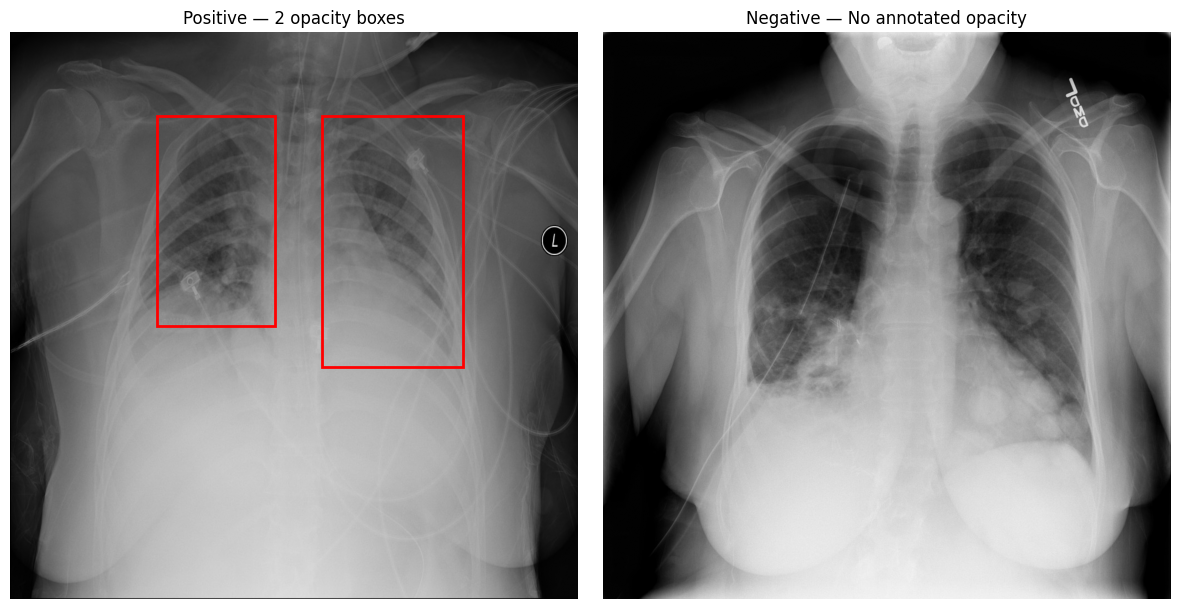

Figure saved: /kaggle/working/rsna_pneumonia/results/figures/dataset_annotation_examples.png


In [6]:

# ============================================================
# Visual Exploration: Chest X-rays & Reference Boxes
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, (label, patient_id) in zip(
    axes,
    [("Positive", sample_ids[0]), ("Negative", sample_ids[1])]
):
    ds = pydicom.dcmread(IMAGES_DIR / f"{patient_id}.dcm")
    ax.imshow(ds.pixel_array, cmap="gray", vmin=0, vmax=255)

    # Draw reference bounding boxes for positive images
    if label == "Positive":
        boxes = positive[positive["patientId"] == patient_id]

        for _, box in boxes.iterrows():
            rect = Rectangle(
                (box["x"], box["y"]),
                box["width"],
                box["height"],
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)

        ax.set_title(f"Positive — {len(boxes)} opacity boxes")
    else:
        ax.set_title("Negative — No annotated opacity")

    ax.axis("off")

# Save figure for reporting and documentation
figure_path = FIGURES_DIR / "dataset_annotation_examples.png"

plt.tight_layout()
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Figure saved: {figure_path}")


In [7]:

# ============================================================
# Pre-Split Verification: Dataset Files & Patient Metadata
# ============================================================

# Inspect available dataset metadata files
print("Dataset metadata files:")
for path in sorted(DATASET_ROOT.rglob("*.csv")):
    print(f"  {path.relative_to(DATASET_ROOT)}")

# Inspect patient/study identifiers from sample DICOM files
print("\nDICOM identifier metadata:")

for patient_id in sample_ids:
    ds = pydicom.dcmread(
        IMAGES_DIR / f"{patient_id}.dcm",
        stop_before_pixels=True
    )

    print(f"\nFilename ID       : {patient_id}")
    print(f"DICOM PatientID   : {ds.get('PatientID', 'N/A')}")
    print(f"StudyInstanceUID  : {ds.get('StudyInstanceUID', 'N/A')}")
    print(f"SeriesInstanceUID : {ds.get('SeriesInstanceUID', 'N/A')}")
    print(f"SOPInstanceUID    : {ds.get('SOPInstanceUID', 'N/A')}")


Dataset metadata files:
  stage_2_detailed_class_info.csv
  stage_2_sample_submission.csv
  stage_2_train_labels.csv

DICOM identifier metadata:

Filename ID       : 00436515-870c-4b36-a041-de91049b9ab4
DICOM PatientID   : 00436515-870c-4b36-a041-de91049b9ab4
StudyInstanceUID  : 1.2.276.0.7230010.3.1.2.8323329.6379.1517874325.469568
SeriesInstanceUID : 1.2.276.0.7230010.3.1.3.8323329.6379.1517874325.469567
SOPInstanceUID    : 1.2.276.0.7230010.3.1.4.8323329.6379.1517874325.469569

Filename ID       : 0004cfab-14fd-4e49-80ba-63a80b6bddd6
DICOM PatientID   : 0004cfab-14fd-4e49-80ba-63a80b6bddd6
StudyInstanceUID  : 1.2.276.0.7230010.3.1.2.8323329.28530.1517874485.775525
SeriesInstanceUID : 1.2.276.0.7230010.3.1.3.8323329.28530.1517874485.775524
SOPInstanceUID    : 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526


In [8]:

# ============================================================
# Full Dataset Metadata Verification
# ============================================================

from tqdm.auto import tqdm

# Inspect detailed class information
class_info = pd.read_csv(
    DATASET_ROOT / "stage_2_detailed_class_info.csv"
)

print("Detailed class distribution:")
print(class_info["class"].value_counts())

print("\nClass information preview:")
display(class_info.head())

# Read DICOM headers only (no pixel decoding)
metadata = []

dicom_files = sorted(IMAGES_DIR.glob("*.dcm"))

for path in tqdm(dicom_files, desc="Checking DICOM metadata", unit="image"):
    ds = pydicom.dcmread(
        path,
        stop_before_pixels=True,
        specific_tags=[
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SOPInstanceUID",
        ],
    )

    metadata.append({
        "filename_id": path.stem,
        "patient_id": ds.get("PatientID"),
        "study_uid": ds.get("StudyInstanceUID"),
        "series_uid": ds.get("SeriesInstanceUID"),
        "sop_uid": ds.get("SOPInstanceUID"),
    })

metadata_df = pd.DataFrame(metadata)

print("\nMetadata verification:")
print(f"Images checked        : {len(metadata_df):,}")
print(f"Unique DICOM patients : {metadata_df['patient_id'].nunique():,}")
print(f"Unique studies        : {metadata_df['study_uid'].nunique():,}")
print(f"Unique series         : {metadata_df['series_uid'].nunique():,}")
print(f"Unique SOP instances  : {metadata_df['sop_uid'].nunique():,}")
print(f"Filename/Patient match: {(metadata_df['filename_id'] == metadata_df['patient_id']).all()}")

print("\nMissing metadata values:")
print(metadata_df.isna().sum())


Detailed class distribution:
class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851
Name: count, dtype: int64

Class information preview:


,patientId,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,Lung Opacity


Checking DICOM metadata:   0%|          | 0/26684 [00:00<?, ?image/s]


Metadata verification:
Images checked        : 26,684
Unique DICOM patients : 26,684
Unique studies        : 26,684
Unique series         : 26,684
Unique SOP instances  : 26,684
Filename/Patient match: True

Missing metadata values:
filename_id    0
patient_id     0
study_uid      0
series_uid     0
sop_uid        0
dtype: int64


In [9]:

# ============================================================
# Stratified Train / Validation / Test Split
# ============================================================

from sklearn.model_selection import train_test_split

# One record per image
image_info = (
    annotations.groupby("patientId")["Target"]
    .agg(target="max", box_count="sum")
    .reset_index()
)

# Attach detailed image-level class information
image_classes = class_info.drop_duplicates("patientId")

assert image_classes["patientId"].is_unique
assert len(image_classes) == len(image_info)

image_info = image_info.merge(
    image_classes, on="patientId", validate="one_to_one"
)

# Define stratification groups
def assign_stratum(row):
    if row["target"] == 1:
        return "Single opacity" if row["box_count"] == 1 else "Multiple opacities"
    return row["class"]

image_info["stratum"] = image_info.apply(assign_stratum, axis=1)

# 70% training, 15% validation, 15% testing
train_df, remaining_df = train_test_split(
    image_info,
    test_size=0.30,
    stratify=image_info["stratum"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["stratum"],
    random_state=SEED,
)

# Assign split names
train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")

split_manifest = pd.concat(
    [train_df, val_df, test_df], ignore_index=True
)

# Validate split integrity
assert len(split_manifest) == len(image_info)
assert split_manifest["patientId"].is_unique
assert set(split_manifest["patientId"]) == set(metadata_df["patient_id"])

# Verify consistency between detailed classes and detection targets
assert (
    (split_manifest["class"] == "Lung Opacity")
    == (split_manifest["target"] == 1)
).all()

# Save split assignments
split_path = DATA_DIR / "split_manifest.csv"
split_manifest.to_csv(split_path, index=False)

# Report image-level distributions
print("Images per split:")
print(split_manifest["split"].value_counts().reindex(["train", "val", "test"]))

print("\nStratification distribution:")
print(pd.crosstab(
    split_manifest["split"],
    split_manifest["stratum"],
    normalize="index"
).mul(100).round(2))

print(f"\nSplit manifest saved: {split_path}")
print("Split integrity: PASSED")


Images per split:
split
train    18678
val       4003
test      4003
Name: count, dtype: int64

Stratification distribution:
stratum  Multiple opacities  No Lung Opacity / Not Normal  Normal  \
split                                                               
test                  12.72                         44.32   33.18   
train                 12.74                         44.30   33.17   
val                   12.74                         44.29   33.18   

stratum  Single opacity  
split                    
test               9.79  
train              9.80  
val                9.79  

Split manifest saved: /kaggle/working/rsna_pneumonia/data/split_manifest.csv
Split integrity: PASSED


In [10]:

# ============================================================
# DICOM-to-PNG Conversion (Parallel & Resumable)
# ============================================================

from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import os

YOLO_ROOT = DATA_DIR / "yolo_dataset"
NUM_WORKERS = 4

# Prepare output directories
for split in ["train", "val", "test"]:
    (YOLO_ROOT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

def convert_dicom(row):
    patient_id, split = row
    source = IMAGES_DIR / f"{patient_id}.dcm"
    destination = YOLO_ROOT / "images" / split / f"{patient_id}.png"
    temporary = destination.with_suffix(".tmp.png")

    try:
        # Resume from an existing valid PNG
        if destination.exists():
            try:
                with Image.open(destination) as img:
                    img.verify()
                return "skipped", patient_id
            except Exception:
                destination.unlink()

        # Read and validate DICOM image
        ds = pydicom.dcmread(source)
        pixels = ds.pixel_array

        if pixels.ndim != 2 or pixels.dtype != np.uint8:
            raise ValueError(
                f"Unexpected pixel format: {pixels.shape}, {pixels.dtype}"
            )

        photometric = ds.get("PhotometricInterpretation")

        if photometric == "MONOCHROME1":
            pixels = 255 - pixels
        elif photometric != "MONOCHROME2":
            raise ValueError(f"Unsupported photometric mode: {photometric}")

        # Fast, lossless PNG encoding
        Image.fromarray(pixels).save(
            temporary,
            format="PNG",
            compress_level=1
        )

        # Atomically publish completed image
        os.replace(temporary, destination)

        return "converted", patient_id

    except Exception as exc:
        temporary.unlink(missing_ok=True)
        return "failed", (patient_id, str(exc))


# Convert according to the fixed split manifest
tasks = list(
    split_manifest[["patientId", "split"]]
    .itertuples(index=False, name=None)
)

converted = 0
skipped = 0
failed = []

with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    futures = [executor.submit(convert_dicom, row) for row in tasks]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Converting DICOM images",
        unit="image"
    ):
        status, result = future.result()

        if status == "converted":
            converted += 1
        elif status == "skipped":
            skipped += 1
        else:
            failed.append(result)

# Conversion summary
print(f"\nNewly converted : {converted:,}")
print(f"Already existing: {skipped:,}")
print(f"Failed          : {len(failed):,}")
print(f"Total processed : {converted + skipped + len(failed):,}")
print(f"Output directory: {YOLO_ROOT / 'images'}")

if failed:
    print("\nFirst conversion errors:")
    for patient_id, error in failed[:5]:
        print(f"{patient_id}: {error}")


Converting DICOM images:   0%|          | 0/26684 [00:00<?, ?image/s]


Newly converted : 26,684
Already existing: 0
Failed          : 0
Total processed : 26,684
Output directory: /kaggle/working/rsna_pneumonia/data/yolo_dataset/images


In [11]:

# ============================================================
# DICOM-to-PNG Conversion Validation
# ============================================================

from tqdm.auto import tqdm

# Verify output counts and exact image IDs for each split
for split in ["train", "val", "test"]:
    expected_ids = set(
        split_manifest.loc[
            split_manifest["split"] == split, "patientId"
        ]
    )
    actual_ids = {
        path.stem
        for path in (YOLO_ROOT / "images" / split).glob("*.png")
    }

    assert actual_ids == expected_ids, f"{split}: image ID mismatch"
    print(f"{split:5s}: {len(actual_ids):,} PNG files — PASSED")

# Sample images across all splits and both target classes
sample_df = (
    split_manifest.groupby(["split", "target"], group_keys=False)
    .sample(n=5, random_state=SEED)
)

for row in tqdm(
    sample_df.itertuples(index=False),
    total=len(sample_df),
    desc="Validating image pixels",
    unit="image"
):
    ds = pydicom.dcmread(
        IMAGES_DIR / f"{row.patientId}.dcm"
    )

    original = ds.pixel_array

    if ds.PhotometricInterpretation == "MONOCHROME1":
        original = 255 - original

    png_path = (
        YOLO_ROOT / "images" / row.split / f"{row.patientId}.png"
    )

    with Image.open(png_path) as img:
        assert img.mode == "L", f"Unexpected mode: {img.mode}"
        converted_pixels = np.array(img)

    assert original.shape == converted_pixels.shape
    assert np.array_equal(original, converted_pixels), (
        f"Pixel mismatch: {row.patientId}"
    )

print("\nConversion integrity: PASSED")
print(f"Pixel-equivalent images checked: {len(sample_df)}")


train: 18,678 PNG files — PASSED
val  : 4,003 PNG files — PASSED
test : 4,003 PNG files — PASSED


Validating image pixels:   0%|          | 0/30 [00:00<?, ?image/s]


Conversion integrity: PASSED
Pixel-equivalent images checked: 30


In [12]:

# ============================================================
# RSNA Annotations to YOLO Labels
# ============================================================

from tqdm.auto import tqdm

# Prepare label directories
for split in ["train", "val", "test"]:
    (YOLO_ROOT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# Group positive bounding boxes by image
annotations_by_id = {
    patient_id: group
    for patient_id, group in positive.groupby("patientId")
}

label_count = 0
box_count = 0

for row in tqdm(
    split_manifest.itertuples(index=False),
    total=len(split_manifest),
    desc="Generating YOLO labels",
    unit="image"
):
    image_path = (
        YOLO_ROOT / "images" / row.split / f"{row.patientId}.png"
    )
    label_path = (
        YOLO_ROOT / "labels" / row.split / f"{row.patientId}.txt"
    )

    # Read original image dimensions
    with Image.open(image_path) as img:
        image_width, image_height = img.size

    lines = []

    if row.patientId in annotations_by_id:
        boxes = annotations_by_id[row.patientId]

        for box in boxes.itertuples(index=False):
            # Convert top-left coordinates to normalized YOLO format
            x_center = (box.x + box.width / 2) / image_width
            y_center = (box.y + box.height / 2) / image_height
            width = box.width / image_width
            height = box.height / image_height

            # Check bounding-box boundaries
            assert 0 <= x_center - width / 2
            assert x_center + width / 2 <= 1
            assert 0 <= y_center - height / 2
            assert y_center + height / 2 <= 1
            assert width > 0 and height > 0

            lines.append(
                f"0 {x_center:.8f} {y_center:.8f} "
                f"{width:.8f} {height:.8f}"
            )

            box_count += 1

    # Empty file for images without annotated opacities
    label_path.write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8"
    )

    label_count += 1

print(f"\nLabel files created : {label_count:,}")
print(f"Bounding boxes      : {box_count:,}")
print(f"Negative label files: {label_count - len(annotations_by_id):,}")
print(f"Output directory    : {YOLO_ROOT / 'labels'}")

assert label_count == len(split_manifest)
assert box_count == len(positive)

print("\nYOLO label generation: PASSED")


Generating YOLO labels:   0%|          | 0/26684 [00:00<?, ?image/s]


Label files created : 26,684
Bounding boxes      : 9,555
Negative label files: 20,672
Output directory    : /kaggle/working/rsna_pneumonia/data/yolo_dataset/labels

YOLO label generation: PASSED


In [13]:

# ============================================================
# YOLO Dataset Configuration
# ============================================================

import yaml

dataset_config = {
    "path": str(YOLO_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": {0: "pulmonary_opacity"},
}

DATA_YAML = YOLO_ROOT / "data.yaml"

with open(DATA_YAML, "w", encoding="utf-8") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

# Verify the saved configuration
with open(DATA_YAML, encoding="utf-8") as file:
    saved_config = yaml.safe_load(file)

assert saved_config == dataset_config

for split in ["train", "val", "test"]:
    assert (YOLO_ROOT / saved_config[split]).is_dir()
    assert (YOLO_ROOT / "labels" / split).is_dir()

print(yaml.safe_dump(saved_config, sort_keys=False))
print(f"Configuration saved: {DATA_YAML}")
print("YOLO dataset configuration: PASSED")


path: /kaggle/working/rsna_pneumonia/data/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: pulmonary_opacity

Configuration saved: /kaggle/working/rsna_pneumonia/data/yolo_dataset/data.yaml
YOLO dataset configuration: PASSED


In [14]:

# ============================================================
# Phase 2.5A — YOLO Dataset Integrity Validation (Updated)
# ============================================================

from tqdm.auto import tqdm
import pandas as pd

# Tolerance for 8-decimal YOLO coordinate rounding
EPS = 1e-7

validation_rows = []
errors = []

for row in tqdm(
    split_manifest.itertuples(index=False),
    total=len(split_manifest),
    desc="Validating YOLO dataset",
    unit="image"
):
    image_path = (
        YOLO_ROOT / "images" / row.split / f"{row.patientId}.png"
    )
    label_path = (
        YOLO_ROOT / "labels" / row.split / f"{row.patientId}.txt"
    )

    try:
        # 1. Verify image-label pairing
        assert image_path.is_file(), "Missing image"
        assert label_path.is_file(), "Missing label"

        # 2. Verify annotation count
        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

        assert len(lines) == row.box_count, (
            "Bounding-box count mismatch"
        )

        # 3. Validate every YOLO annotation
        for line in lines:
            values = list(map(float, line.split()))

            assert len(values) == 5, "Invalid YOLO annotation"
            assert values[0] == 0, "Unexpected class ID"

            xc, yc, w, h = values[1:]

            # Valid normalized dimensions
            assert 0 < w <= 1 and 0 < h <= 1, (
                "Invalid bounding-box dimensions"
            )

            # Allow negligible serialization rounding errors
            assert -EPS <= xc - w / 2 <= 1 + EPS, (
                "Invalid left boundary"
            )
            assert -EPS <= xc + w / 2 <= 1 + EPS, (
                "Invalid right boundary"
            )
            assert -EPS <= yc - h / 2 <= 1 + EPS, (
                "Invalid top boundary"
            )
            assert -EPS <= yc + h / 2 <= 1 + EPS, (
                "Invalid bottom boundary"
            )

        validation_rows.append({
            "split": row.split,
            "images": 1,
            "positive": int(len(lines) > 0),
            "boxes": len(lines),
        })

    except Exception as exc:
        errors.append((row.patientId, str(exc)))

# 4. Summarize validation results
validation_df = pd.DataFrame(validation_rows)

print("\nDataset validation summary:")

if not validation_df.empty:
    summary = validation_df.groupby("split")[
        ["images", "positive", "boxes"]
    ].sum()

    print(summary.to_string())

print(f"\nValidation errors: {len(errors)}")

if errors:
    print("\nFirst validation errors:")
    for patient_id, error in errors[:5]:
        print(f"{patient_id}: {error}")

# 5. Final integrity assertions
assert not errors, "Dataset validation failed"
assert validation_df["images"].sum() == 26684
assert validation_df["positive"].sum() == 6012
assert validation_df["boxes"].sum() == 9555

print("\nYOLO dataset integrity: PASSED")


Validating YOLO dataset:   0%|          | 0/26684 [00:00<?, ?image/s]


Dataset validation summary:
       images  positive  boxes
split                         
test     4003       901   1434
train   18678      4209   6684
val      4003       902   1437

Validation errors: 0

YOLO dataset integrity: PASSED


Analyzing opacity sizes:   0%|          | 0/6012 [00:00<?, ?image/s]


Opacity bounding-box area (% of image):
       count   mean  median    min     max
split                                     
test    1434  7.446   6.280  0.402  27.425
train   6684  7.427   6.266  0.221  35.399
val     1437  7.185   5.824  0.294  30.225

Overall area percentiles:
0.10     2.174
0.25     3.580
0.50     6.183
0.75    10.156
0.90    14.461


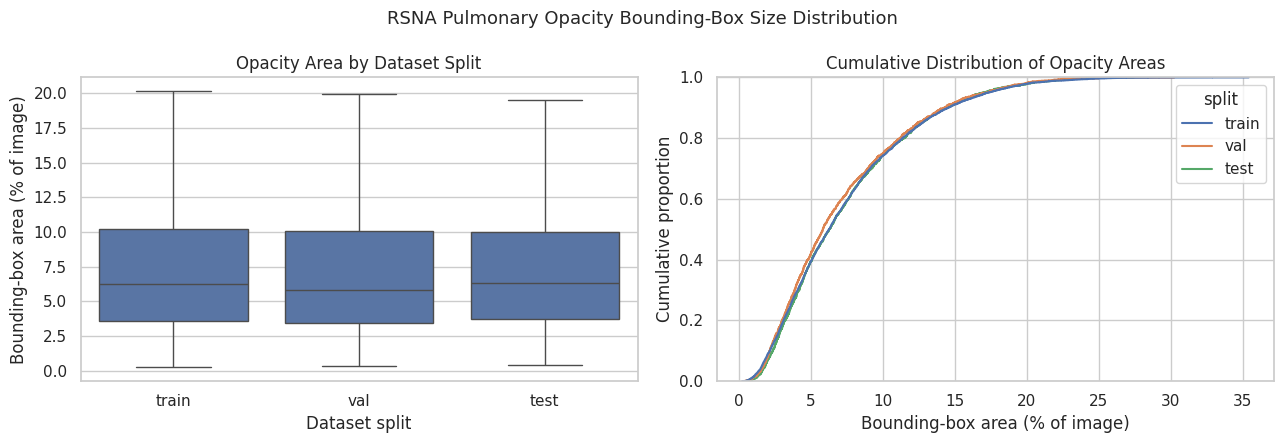


Figure saved: /kaggle/working/rsna_pneumonia/results/figures/opacity_box_size_distribution.png


In [15]:

# ============================================================
# Phase 2.5B — Bounding-Box Size Distribution
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

box_records = []

# Read all positive YOLO annotations
positive_manifest = split_manifest[
    split_manifest["target"] == 1
]

for row in tqdm(
    positive_manifest.itertuples(index=False),
    total=len(positive_manifest),
    desc="Analyzing opacity sizes",
    unit="image"
):
    label_path = (
        YOLO_ROOT / "labels" / row.split / f"{row.patientId}.txt"
    )

    for line in label_path.read_text().splitlines():
        class_id, xc, yc, w, h = map(float, line.split())

        box_records.append({
            "split": row.split,
            "width": w,
            "height": h,
            "area_pct": 100 * w * h,
        })

box_df = pd.DataFrame(box_records)

assert len(box_df) == 9555

# Numerical summary
summary = (
    box_df.groupby("split")["area_pct"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

print("\nOpacity bounding-box area (% of image):")
print(summary.to_string())

print("\nOverall area percentiles:")
print(
    box_df["area_pct"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    .round(3)
    .to_string()
)

# Visualization
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

split_order = ["train", "val", "test"]

sns.boxplot(
    data=box_df,
    x="split",
    y="area_pct",
    order=split_order,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Opacity Area by Dataset Split")
axes[0].set_xlabel("Dataset split")
axes[0].set_ylabel("Bounding-box area (% of image)")

sns.ecdfplot(
    data=box_df,
    x="area_pct",
    hue="split",
    hue_order=split_order,
    ax=axes[1]
)
axes[1].set_title("Cumulative Distribution of Opacity Areas")
axes[1].set_xlabel("Bounding-box area (% of image)")
axes[1].set_ylabel("Cumulative proportion")

fig.suptitle(
    "RSNA Pulmonary Opacity Bounding-Box Size Distribution",
    fontsize=13
)

plt.tight_layout()

figure_path = FIGURES_DIR / "opacity_box_size_distribution.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"\nFigure saved: {figure_path}")


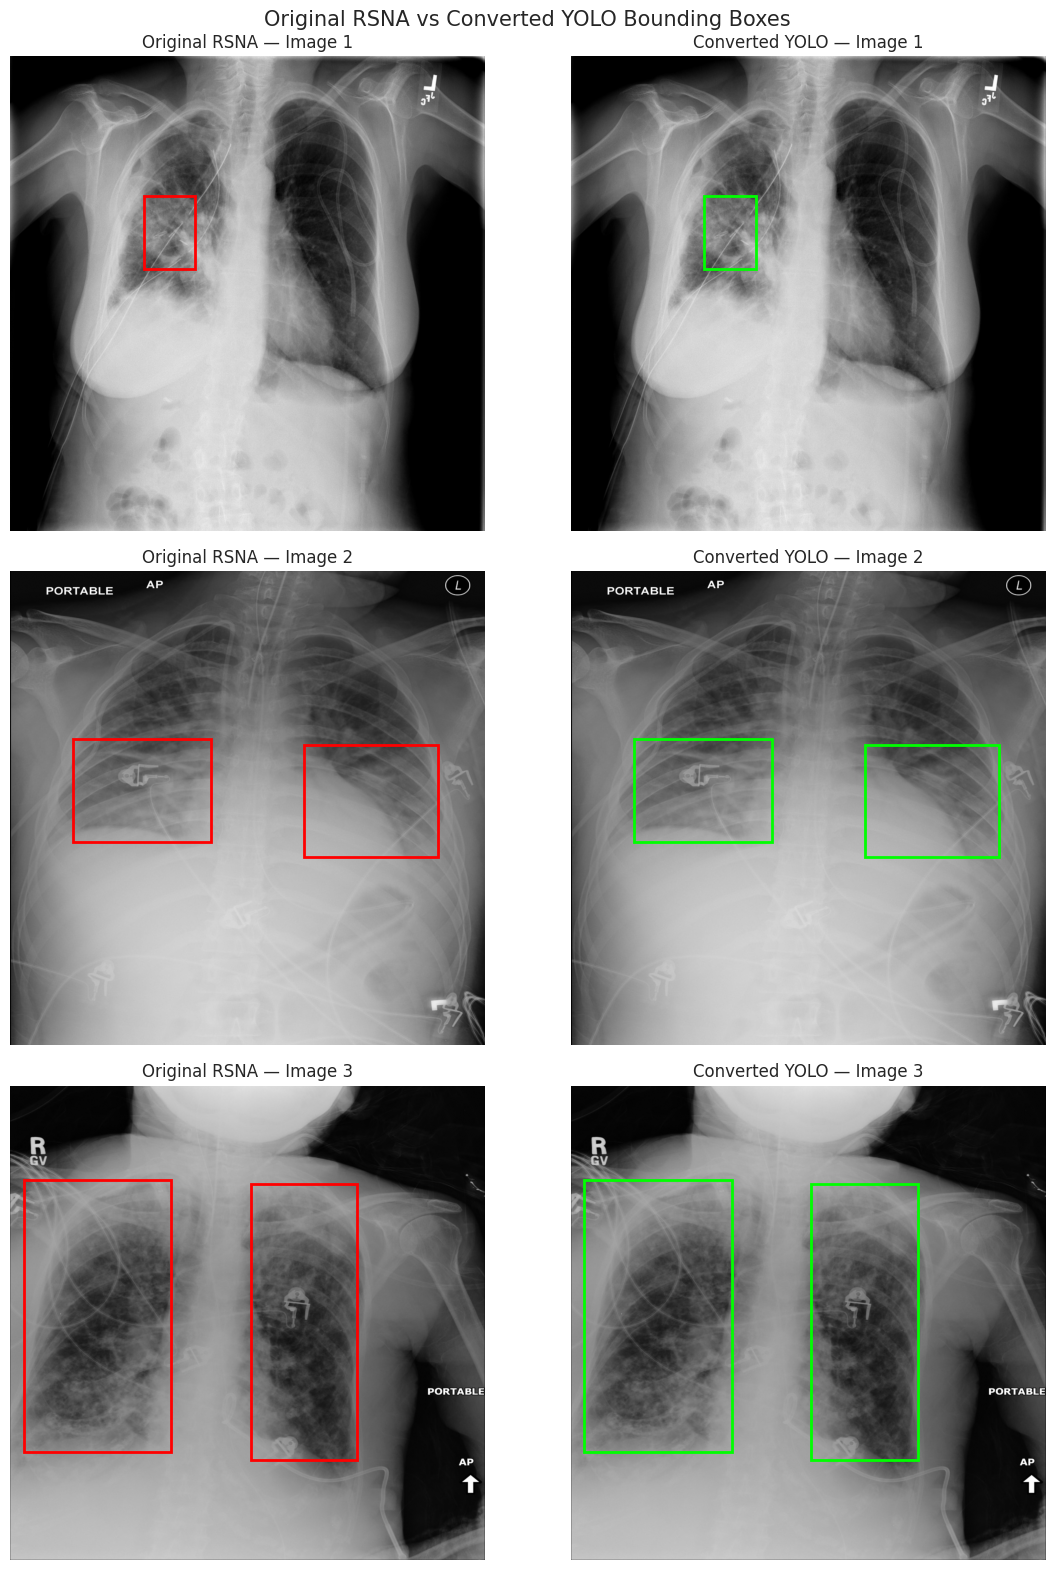

Visualization saved: /kaggle/working/rsna_pneumonia/results/figures/rsna_vs_yolo_box_validation.png
Images visually compared: 3


In [16]:

# ============================================================
# Phase 2.5C — Visual Verification of YOLO Bounding Boxes
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Reproducible sample of three positive training images
sample_ids = (
    split_manifest.loc[
        (split_manifest["split"] == "train")
        & (split_manifest["target"] == 1),
        "patientId"
    ]
    .sample(n=3, random_state=SEED)
    .tolist()
)

fig, axes = plt.subplots(3, 2, figsize=(12, 16))

for i, patient_id in enumerate(sample_ids):
    image_path = (
        YOLO_ROOT / "images" / "train" / f"{patient_id}.png"
    )
    label_path = (
        YOLO_ROOT / "labels" / "train" / f"{patient_id}.txt"
    )

    with Image.open(image_path) as img:
        image = np.array(img)

    H, W = image.shape

    # Original RSNA bounding boxes
    original_boxes = annotations.loc[
        (annotations["patientId"] == patient_id)
        & (annotations["Target"] == 1)
    ]

    # Converted YOLO bounding boxes
    yolo_lines = label_path.read_text().splitlines()

    for j in range(2):
        axes[i, j].imshow(image, cmap="gray")
        axes[i, j].axis("off")

    for box in original_boxes.itertuples(index=False):
        rect = patches.Rectangle(
            (box.x, box.y),
            box.width,
            box.height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
        axes[i, 0].add_patch(rect)

    for line in yolo_lines:
        class_id, xc, yc, w, h = map(float, line.split())

        box_width = w * W
        box_height = h * H
        x_min = xc * W - box_width / 2
        y_min = yc * H - box_height / 2

        rect = patches.Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        axes[i, 1].add_patch(rect)

    axes[i, 0].set_title(f"Original RSNA — Image {i + 1}")
    axes[i, 1].set_title(f"Converted YOLO — Image {i + 1}")

fig.suptitle(
    "Original RSNA vs Converted YOLO Bounding Boxes",
    fontsize=15
)

plt.tight_layout()

figure_path = FIGURES_DIR / "rsna_vs_yolo_box_validation.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Visualization saved: {figure_path}")
print(f"Images visually compared: {len(sample_ids)}")


## 3. Controlled YOLO11s Training Configuration

In [17]:

# ============================================================
# 3 — Controlled YOLO11s Training Configuration
# ============================================================

import ultralytics.data.augment as augment_module

# Disable optional default Albumentations transforms.
Albumentations = augment_module.Albumentations

if not hasattr(Albumentations, "_original_init"):
    Albumentations._original_init = Albumentations.__init__

def controlled_albumentations_init(
    self, p=1.0, transforms=None, flip_idx=None
):
    Albumentations._original_init(
        self,
        p=p,
        transforms=[] if transforms is None else transforms,
        flip_idx=flip_idx,
    )

Albumentations.__init__ = controlled_albumentations_init

# Shared configuration: only imgsz and run name change.
TRAIN_CONFIG = {
    "data": str(DATA_YAML),
    "epochs": 30,
    "batch": 8,
    "device": 0,
    "workers": 2,
    "seed": 42,
    "deterministic": True,
    "optimizer": "SGD",
    "lr0": 0.01,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "amp": True,
    "patience": 0,
    "fraction": 1.0,
    "multi_scale": 0.0,
    "rect": False,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "copy_paste": 0.0,
    "cutmix": 0.0,
    "val": True,
    "save": True,
    "save_period": -1,
    "plots": True,
    "project": str(RESULTS_DIR / "training"),
    "exist_ok": False,
}

# Verify configuration and augmentation control.
assert DATA_YAML.is_file()
assert len(Albumentations().transform.transforms) == 0

print("YOLO11s experimental configuration: READY")
print("Resolutions: 640 and 800")
print("Epochs: 30 | Batch size: 8 | Seed: 42")
print("Optional Albumentations transforms: disabled")


albumentations: 
YOLO11s experimental configuration: READY
Resolutions: 640 and 800
Epochs: 30 | Batch size: 8 | Seed: 42
Optional Albumentations transforms: disabled


## 4. Phase 4 - Train YOLO11s modes

In [18]:

# ============================================================
# Phase 4 — Train YOLO11s at 640 × 640
# ============================================================

from ultralytics import YOLO
import time

# Initialize a fresh model from pretrained weights.
model_640 = YOLO("yolo11s.pt")

# Reuse the controlled experimental configuration.
config_640 = TRAIN_CONFIG.copy()
config_640.update({
    "imgsz": 640,
    "name": "yolo11s_640",
})

print("Starting YOLO11s training at 640 × 640...")

start_time = time.perf_counter()

results_640 = model_640.train(**config_640)

training_time_640 = time.perf_counter() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {training_time_640 / 3600:.2f} hours")
print(f"Results saved to: {model_640.trainer.save_dir}")


Starting YOLO11s training at 640 × 640...
Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rsna_pneumonia/data/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30       2.6G      1.928      2.851      1.854          3        640: 100% ━━━━━━━━━━━━ 2335/2335 8.1it/s 4:470.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 251/251 5.1it/s 49.2s0.2ss
                   all       4003       1437      0.322      0.127      0.124     0.0389

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30       2.6G      1.933      2.804      1.858          0        640: 100% ━━━━━━━━━━━━ 2335/2335 8.0it/s 4:520.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 251/251 5.1it/s 48.8s0.1ss
                   all       4003       1437       0.11      0.374      0.127     0.0378

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30       2.6G      1.915      2.776      1.833          4        640: 100% ━━━━━━━━━━━━ 2335/2335 7.9it/s 4:540.2sss
                 C

In [19]:

# ============================================================
# Phase 4 — Summarize Completed YOLO11s 640 Training
# ============================================================

import pandas as pd
from pathlib import Path

run_dir = RESULTS_DIR / "training" / "yolo11s_640"
history_path = run_dir / "results.csv"

assert history_path.exists(), "Training history not found."

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

best_epoch = history["metrics/mAP50-95(B)"].idxmax()
best_row = history.loc[best_epoch]

print("YOLO11s — 640 × 640 Training Summary")
print("=" * 45)
print(f"Completed epochs: {len(history)}")
print(f"Best epoch: {int(best_row['epoch'])}")
print(f"Best validation mAP50: {best_row['metrics/mAP50(B)']:.4f}")
print(f"Best validation mAP50-95: {best_row['metrics/mAP50-95(B)']:.4f}")
print(f"Precision at best epoch: {best_row['metrics/precision(B)']:.4f}")
print(f"Recall at best epoch: {best_row['metrics/recall(B)']:.4f}")

best_model_path = run_dir / "weights" / "best.pt"
last_model_path = run_dir / "weights" / "last.pt"

print(f"\nBest checkpoint exists: {best_model_path.exists()}")
print(f"Last checkpoint exists: {last_model_path.exists()}")


YOLO11s — 640 × 640 Training Summary
Completed epochs: 30
Best epoch: 13
Best validation mAP50: 0.3079
Best validation mAP50-95: 0.1269
Precision at best epoch: 0.4127
Recall at best epoch: 0.3086

Best checkpoint exists: True
Last checkpoint exists: True


In [21]:

# ============================================================
# Phase 4 — Train YOLO11s at 800 × 800
# ============================================================

from ultralytics import YOLO
import time

# Initialize a fresh model from the same pretrained weights.
model_800 = YOLO("yolo11s.pt")

# Reuse the controlled experimental configuration.
config_800 = TRAIN_CONFIG.copy()
config_800.update({
    "imgsz": 800,
    "name": "yolo11s_800",
})

print("Starting YOLO11s training at 800 × 800...")

start_time = time.perf_counter()

results_800 = model_800.train(**config_800)

training_time_800 = time.perf_counter() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {training_time_800 / 3600:.2f} hours")
print(f"Results saved to: {model_800.trainer.save_dir}")


Starting YOLO11s training at 800 × 800...
Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rsna_pneumonia/data/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0

In [22]:

# ============================================================
# Phase 4 — Summarize Completed YOLO11s 800 Training
# ============================================================

import pandas as pd
from pathlib import Path

run_dir = RESULTS_DIR / "training" / "yolo11s_800"
history_path = run_dir / "results.csv"

assert history_path.exists(), "Training history not found."

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

best_epoch = history["metrics/mAP50-95(B)"].idxmax()
best_row = history.loc[best_epoch]

print("YOLO11s — 800 × 800 Training Summary")
print("=" * 45)
print(f"Completed epochs: {len(history)}")
print(f"Best epoch: {int(best_row['epoch'])}")
print(f"Best validation mAP50: {best_row['metrics/mAP50(B)']:.4f}")
print(f"Best validation mAP50-95: {best_row['metrics/mAP50-95(B)']:.4f}")
print(f"Precision at best epoch: {best_row['metrics/precision(B)']:.4f}")
print(f"Recall at best epoch: {best_row['metrics/recall(B)']:.4f}")

best_model_path = run_dir / "weights" / "best.pt"
last_model_path = run_dir / "weights" / "last.pt"

print(f"\nBest checkpoint exists: {best_model_path.exists()}")
print(f"Last checkpoint exists: {last_model_path.exists()}")


YOLO11s — 800 × 800 Training Summary
Completed epochs: 30
Best epoch: 14
Best validation mAP50: 0.3021
Best validation mAP50-95: 0.1230
Precision at best epoch: 0.3515
Recall at best epoch: 0.3403

Best checkpoint exists: True
Last checkpoint exists: True


## 5. Comparative Training History Visualization

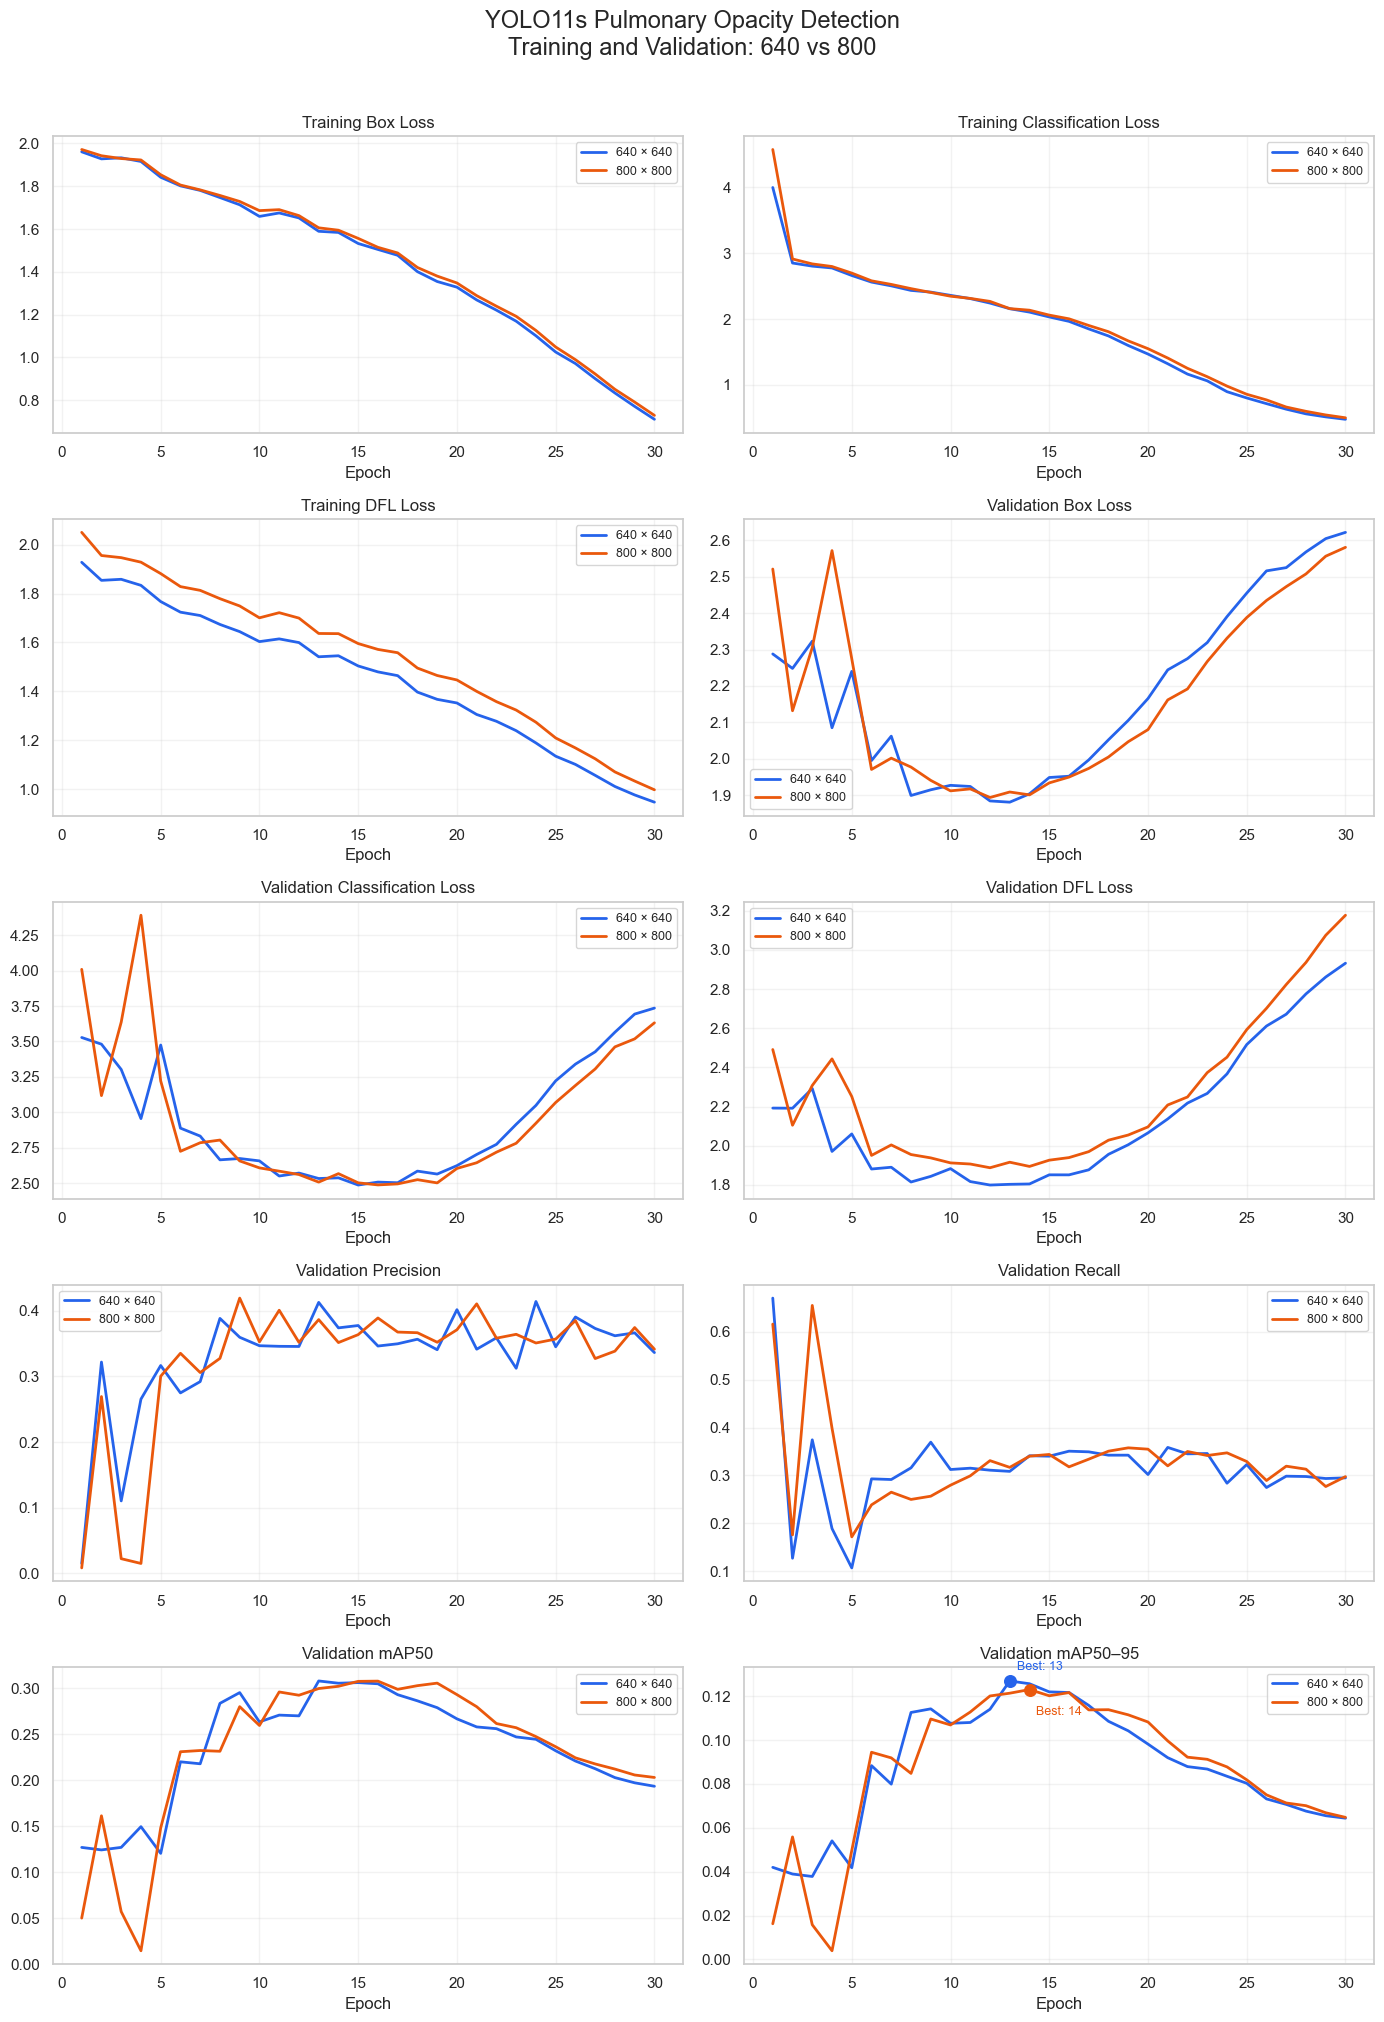

Training comparison figures saved:
/kaggle/working/rsna_pneumonia/results/figures/training_comparison/training_comparison.png
/kaggle/working/rsna_pneumonia/results/figures/training_comparison/training_comparison.pdf


In [24]:

# ============================================================
# Phase 5 — Comparative Training History Visualization
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

training_root = RESULTS_DIR / "training"
figure_dir = FIGURES_DIR / "training_comparison"
figure_dir.mkdir(parents=True, exist_ok=True)

histories = {}

for resolution in (640, 800):
    csv_path = training_root / f"yolo11s_{resolution}" / "results.csv"
    assert csv_path.is_file(), f"Missing: {csv_path}"

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    assert len(df) == 30, f"Incomplete training: {resolution}"
    histories[resolution] = df

metrics = [
    ("train/box_loss", "Training Box Loss"),
    ("train/cls_loss", "Training Classification Loss"),
    ("train/dfl_loss", "Training DFL Loss"),
    ("val/box_loss", "Validation Box Loss"),
    ("val/cls_loss", "Validation Classification Loss"),
    ("val/dfl_loss", "Validation DFL Loss"),
    ("metrics/precision(B)", "Validation Precision"),
    ("metrics/recall(B)", "Validation Recall"),
    ("metrics/mAP50(B)", "Validation mAP50"),
    ("metrics/mAP50-95(B)", "Validation mAP50–95"),
]

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
colors = {640: "#2563EB", 800: "#EA580C"}

for ax, (column, title) in zip(axes.flat, metrics):
    for resolution, df in histories.items():
        ax.plot(
            df["epoch"],
            df[column],
            label=f"{resolution} × {resolution}",
            color=colors[resolution],
            linewidth=2,
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

# Mark best epochs on the mAP50-95 subplot.
map_ax = axes.flat[-1]

for resolution, df in histories.items():
    idx = df["metrics/mAP50-95(B)"].idxmax()
    row = df.loc[idx]

    map_ax.scatter(
        row["epoch"],
        row["metrics/mAP50-95(B)"],
        color=colors[resolution],
        s=70,
        zorder=5,
    )

    map_ax.annotate(
        f"Best: {int(row['epoch'])}",
        (row["epoch"], row["metrics/mAP50-95(B)"]),
        xytext=(5, 8 if resolution == 640 else -18),
        textcoords="offset points",
        fontsize=9,
        color=colors[resolution],
    )

fig.suptitle(
    "YOLO11s Pulmonary Opacity Detection\n"
    "Training and Validation: 640 vs 800",
    fontsize=17,
    fontweight="bold",
    y=1.01,
)

plt.tight_layout()

png_path = figure_dir / "training_comparison.png"
pdf_path = figure_dir / "training_comparison.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Training comparison figures saved:")
print(png_path)
print(pdf_path)


## 6. Phase 6 - Independent Test Evaluation

In [41]:

# ============================================================
# Phase 6.1 — Independent Test Evaluation Setup
# ============================================================

from pathlib import Path
import yaml

# Validation-selected checkpoints from completed training
BEST_MODELS = {
    640: RESULTS_DIR / "training" / "yolo11s_640"
         / "weights" / "best.pt",
    800: RESULTS_DIR / "training" / "yolo11s_800"
         / "weights" / "best.pt",
}

# Resolve the fixed test split from data.yaml
assert DATA_YAML.is_file(), f"Missing dataset config: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

dataset_root = Path(data_cfg["path"])
test_images_dir = dataset_root / data_cfg["test"]
test_labels_dir = dataset_root / "labels" / "test"

# Verify essential evaluation inputs
for resolution, checkpoint in BEST_MODELS.items():
    assert checkpoint.is_file(), (
        f"Missing {resolution} checkpoint: {checkpoint}"
    )

assert test_images_dir.is_dir(), "Test images missing."
assert test_labels_dir.is_dir(), "Test labels missing."

n_images = sum(1 for _ in test_images_dir.glob("*.png"))
n_labels = sum(1 for _ in test_labels_dir.glob("*.txt"))

assert n_images == 4003, f"Unexpected test images: {n_images}"
assert n_labels == 4003, f"Unexpected test labels: {n_labels}"

print("PHASE 6.1 — TEST EVALUATION SETUP")
print("Checkpoints: 640 and 800 verified")
print(f"Test images: {n_images:,}")
print(f"Test labels: {n_labels:,}")
print("Ready for independent test evaluation.")


PHASE 6.1 — TEST EVALUATION SETUP
Checkpoints: 640 and 800 verified
Test images: 4,003
Test labels: 4,003
Ready for independent test evaluation.


In [42]:

# ============================================================
# Phase 6.2.1 — Independent Held-Out Test Evaluation
# YOLO11s: 640 × 640 vs 800 × 800
# ============================================================

from ultralytics import YOLO
import pandas as pd
import json

evaluation_dir = RESULTS_DIR / "test_evaluation"
evaluation_dir.mkdir(parents=True, exist_ok=True)

comparison_path = evaluation_dir / "test_metrics_comparison.csv"

# False = reuse existing test results (recommended)
# True  = explicitly rerun test evaluation
RUN_TEST_EVALUATION = False

if RUN_TEST_EVALUATION:

    # Prevent accidental overwriting of completed results
    assert not comparison_path.exists(), (
        "Existing test results found. Preserve the original "
        "results before running another evaluation."
    )

    test_results = []

    for resolution in (640, 800):

        print(f"\nTEST EVALUATION — {resolution} × {resolution}")

        model = YOLO(str(BEST_MODELS[resolution]))

        metrics = model.val(
            data=str(DATA_YAML),
            split="test",
            imgsz=resolution,
            batch=8,
            device=0,
            workers=2,
            conf=0.001,
            iou=0.7,
            max_det=300,
            augment=False,
            half=False,
            plots=True,
            save_json=False,
            project=str(evaluation_dir),
            name=f"yolo11s_{resolution}_test",
            exist_ok=False,
            verbose=True,
        )

        row = {
            "resolution": resolution,
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50_95": float(metrics.box.map),
        }

        test_results.append(row)

        result_path = (
            evaluation_dir
            / f"yolo11s_{resolution}_test_metrics.json"
        )

        with open(result_path, "w") as f:
            json.dump(row, f, indent=4)

    comparison = pd.DataFrame(test_results)
    comparison.to_csv(comparison_path, index=False)

else:
    assert comparison_path.is_file(), (
        "Saved test metrics are missing. Restore "
        "test_metrics_comparison.csv from your research archive. "
        "Do not rerun evaluation merely because the file is missing."
    )

    comparison = pd.read_csv(comparison_path)

# ------------------------------------------------------------
# Display completed research results
# ------------------------------------------------------------

print("\nPHASE 6.2 — INDEPENDENT TEST RESULTS")
print("=" * 55)
print(comparison.round(4).to_string(index=False))
print(f"\nResults: {comparison_path}")
print(f"Evaluation rerun: {RUN_TEST_EVALUATION}")



PHASE 6.2 — INDEPENDENT TEST RESULTS
 resolution  precision  recall  mAP50  mAP50_95
        640     0.4012  0.3588 0.3264    0.1276
        800     0.3590  0.3643 0.3180    0.1278

Results: /kaggle/working/rsna_pneumonia/results/test_evaluation/test_metrics_comparison.csv
Evaluation rerun: False


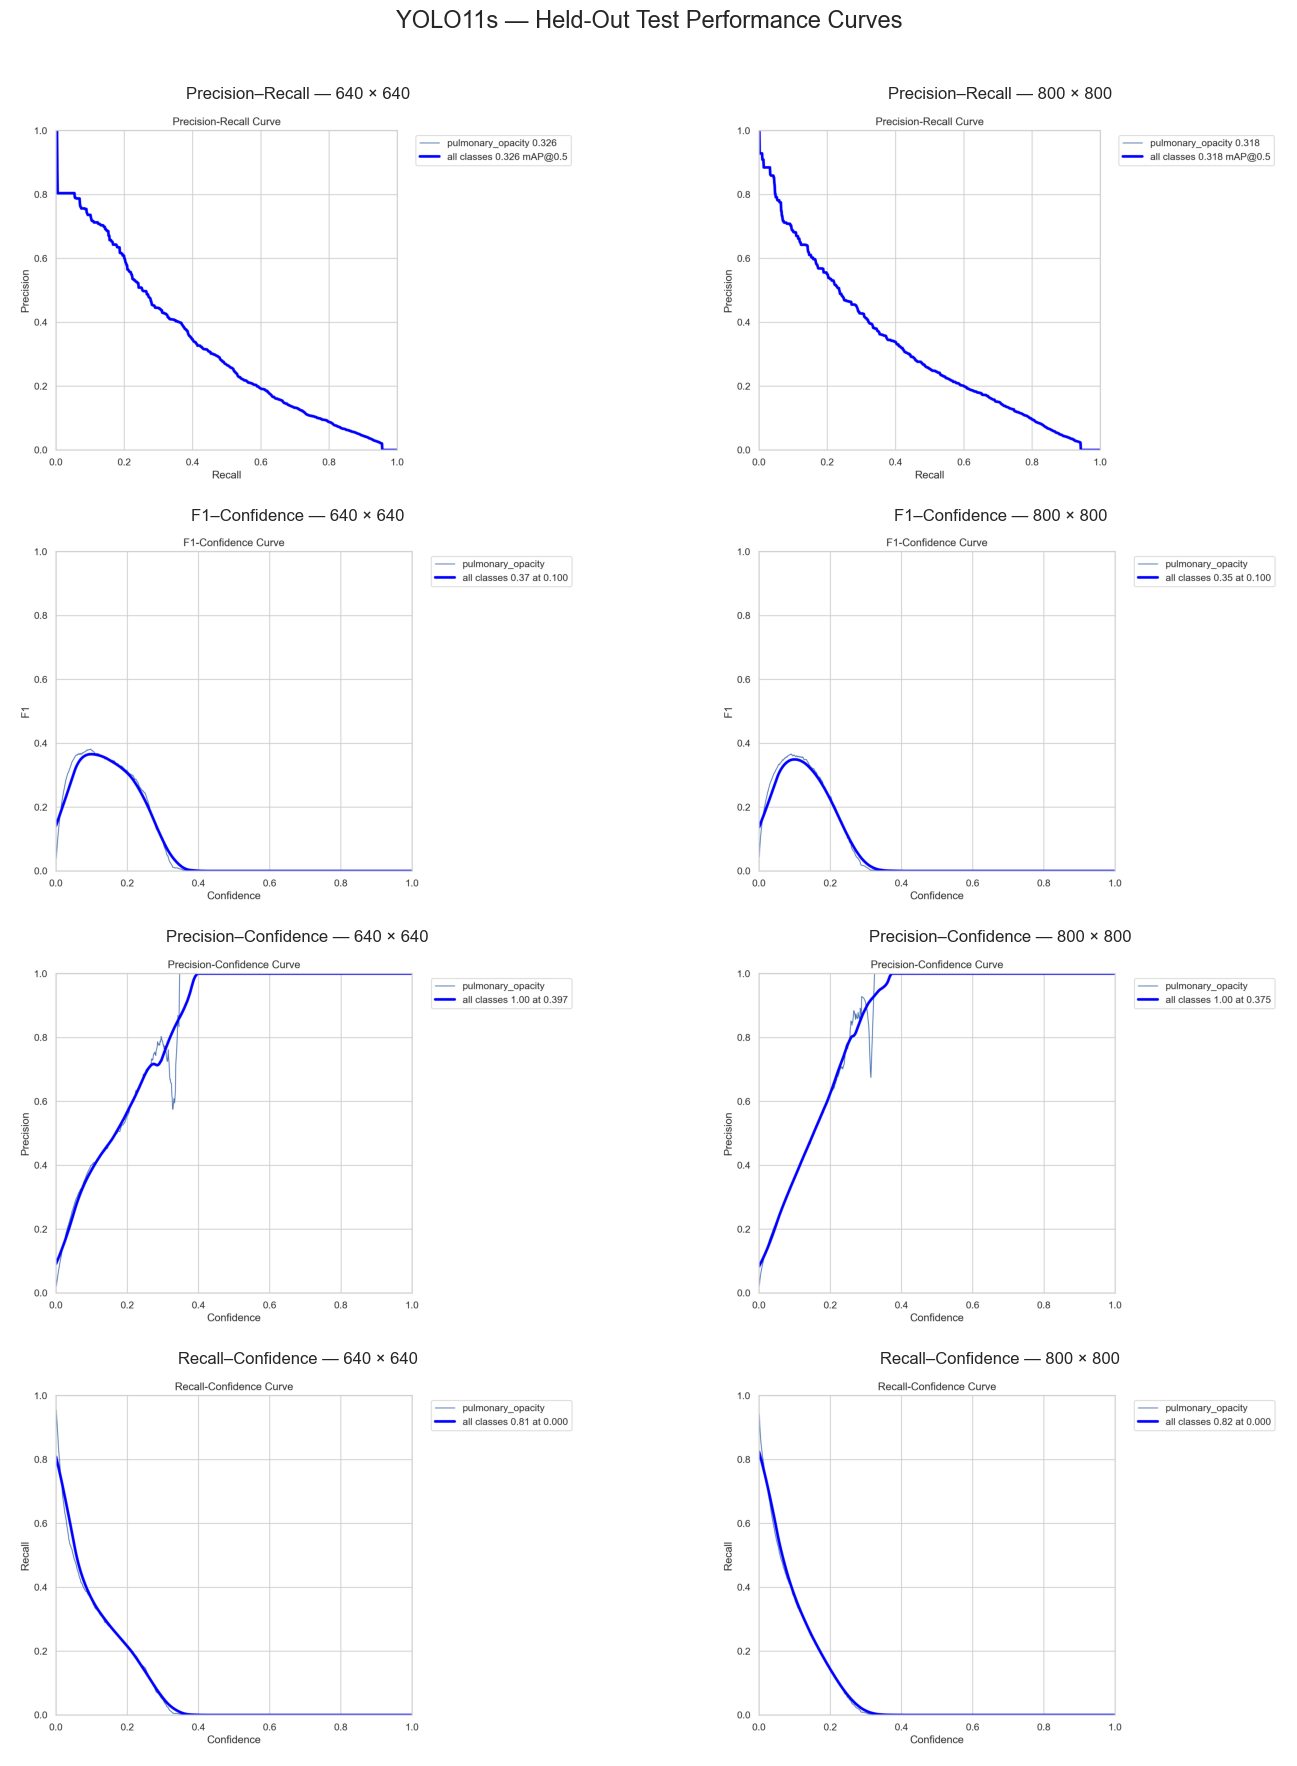

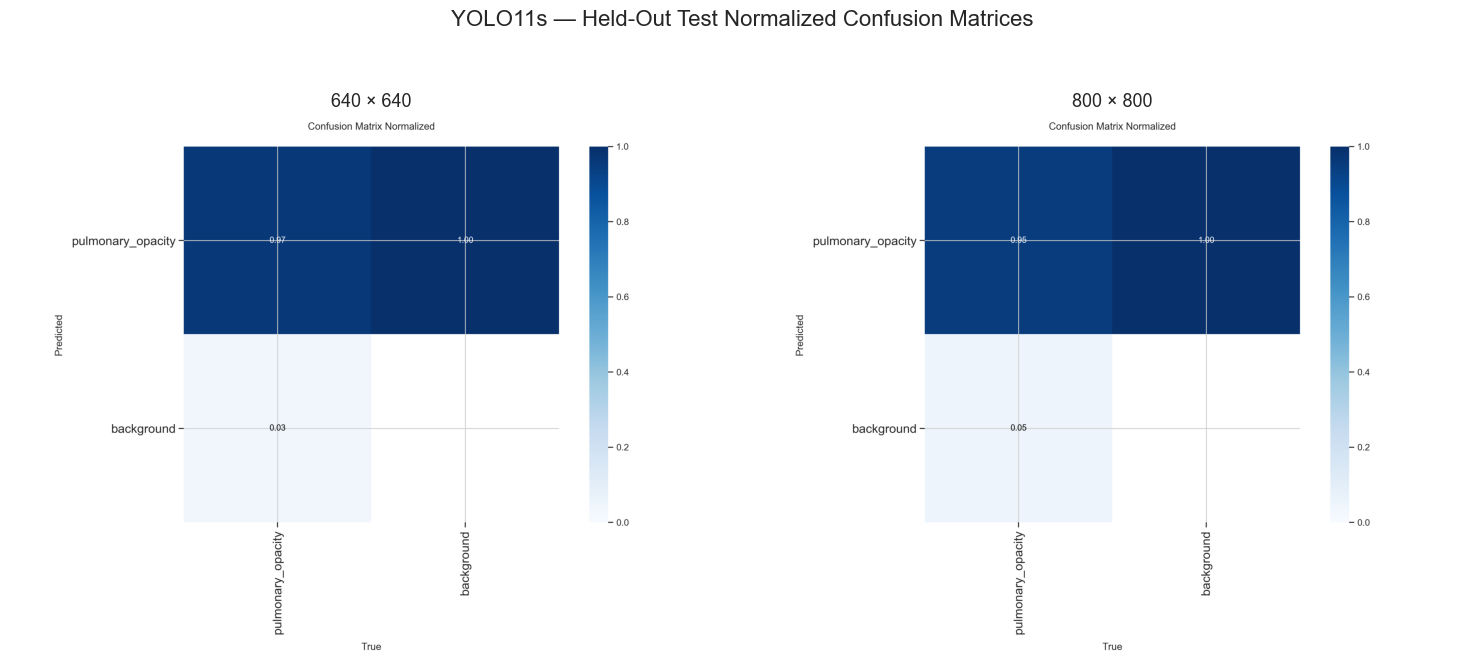


Saved comparison figures:
test_performance_curves_comparison.png: 712.8 KB
test_performance_curves_comparison.pdf: 730.2 KB
test_confusion_matrices_comparison.png: 177.8 KB
test_confusion_matrices_comparison.pdf: 184.7 KB


In [43]:

# ============================================================
# Phase 6.2.2 — Publication-Ready Side-by-Side Test Diagnostics
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

evaluation_dir = RESULTS_DIR / "test_evaluation"
figure_dir = FIGURES_DIR / "test_comparison"
figure_dir.mkdir(parents=True, exist_ok=True)

resolutions = (640, 800)

# Figure 1 — Detection performance curves
curves = [
    ("BoxPR_curve.png", "Precision–Recall"),
    ("BoxF1_curve.png", "F1–Confidence"),
    ("BoxP_curve.png", "Precision–Confidence"),
    ("BoxR_curve.png", "Recall–Confidence"),
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for row, (filename, title) in enumerate(curves):
    for col, resolution in enumerate(resolutions):
        path = evaluation_dir / f"yolo11s_{resolution}_test" / filename
        assert path.is_file(), f"Missing: {path}"

        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(
            f"{title} — {resolution} × {resolution}",
            fontsize=12, fontweight="bold"
        )
        axes[row, col].axis("off")

fig.suptitle(
    "YOLO11s — Held-Out Test Performance Curves",
    fontsize=17, fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.97])

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"test_performance_curves_comparison.{ext}",
        dpi=300, bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# Figure 2 — Normalized confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, resolution in zip(axes, resolutions):
    path = (
        evaluation_dir
        / f"yolo11s_{resolution}_test"
        / "confusion_matrix_normalized.png"
    )
    assert path.is_file(), f"Missing: {path}"

    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"{resolution} × {resolution}",
        fontsize=13, fontweight="bold"
    )
    ax.axis("off")

fig.suptitle(
    "YOLO11s — Held-Out Test Normalized Confusion Matrices",
    fontsize=16, fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.94])

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"test_confusion_matrices_comparison.{ext}",
        dpi=300, bbox_inches="tight"
    )

plt.show()
plt.close(fig)

print("\nSaved comparison figures:")
for name in (
    "test_performance_curves_comparison",
    "test_confusion_matrices_comparison",
):
    for ext in ("png", "pdf"):
        path = figure_dir / f"{name}.{ext}"
        print(f"{path.name}: {path.stat().st_size / 1024:.1f} KB")


In [44]:

# ============================================================
# Phase 6.3.1 — Training-Derived Opacity Size Thresholds
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

train_labels_dir = YOLO_ROOT / "labels" / "train"
assert train_labels_dir.is_dir(), "Training labels not found."

normalized_areas = []

for label_path in sorted(train_labels_dir.glob("*.txt")):
    for line in label_path.read_text().splitlines():
        values = line.split()

        if not values:
            continue

        assert len(values) == 5, f"Invalid label: {label_path}"

        class_id, x, y, w, h = map(float, values)
        assert int(class_id) == 0
        assert 0 < w <= 1 and 0 < h <= 1

        normalized_areas.append(w * h)

areas = np.asarray(normalized_areas, dtype=np.float64)

assert len(areas) == 6684, (
    f"Unexpected training box count: {len(areas)}"
)

small_threshold, large_threshold = np.quantile(
    areas, [1/3, 2/3]
)

thresholds = {
    "source": "training_annotations_only",
    "area_definition": "normalized_width_times_height",
    "method": "training_area_tertiles",
    "training_boxes": int(len(areas)),
    "small_max_area": float(small_threshold),
    "medium_max_area": float(large_threshold),
    "categories": {
        "small": "area <= small_max_area",
        "medium": "small_max_area < area <= medium_max_area",
        "large": "area > medium_max_area"
    }
}

analysis_dir = RESULTS_DIR / "size_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

threshold_path = analysis_dir / "training_size_thresholds.json"


# Preserve the original training-derived thresholds
if threshold_path.is_file():
    with open(threshold_path, "r") as f:
        saved_thresholds = json.load(f)

    assert np.isclose(
        saved_thresholds["small_max_area"],
        thresholds["small_max_area"],
        rtol=0,
        atol=1e-10
    ), "Small-opacity threshold differs from saved research."

    assert np.isclose(
        saved_thresholds["medium_max_area"],
        thresholds["medium_max_area"],
        rtol=0,
        atol=1e-10
    ), "Medium-opacity threshold differs from saved research."

    print("Existing thresholds verified; JSON preserved.")

else:
    with open(threshold_path, "w") as f:
        json.dump(thresholds, f, indent=4)

    print("Training-derived thresholds saved.")


print("=" * 55)
print("PHASE 6.3.1 — TRAINING-DERIVED SIZE THRESHOLDS")
print("=" * 55)
print(f"Training opacity boxes: {len(areas):,}")
print(f"Small:  area <= {small_threshold * 100:.4f}%")
print(
    f"Medium: {small_threshold * 100:.4f}%"
    f" < area <= {large_threshold * 100:.4f}%"
)
print(f"Large:  area > {large_threshold * 100:.4f}%")
print(f"\nThresholds saved: {threshold_path}")


Existing thresholds verified; JSON preserved.
PHASE 6.3.1 — TRAINING-DERIVED SIZE THRESHOLDS
Training opacity boxes: 6,684
Small:  area <= 4.4132%
Medium: 4.4132% < area <= 8.5382%
Large:  area > 8.5382%

Thresholds saved: /kaggle/working/rsna_pneumonia/results/size_analysis/training_size_thresholds.json


PHASE 6.3.2 — SIZE-STRATIFIED RECALL
Source: Previously completed test evaluation
Model training: NOT PERFORMED
Model inference: NOT PERFORMED

DETAILED TEST RESULTS
 resolution size_category  ground_truth_boxes  detected_boxes  recall_at_iou50_conf010
        640         small                 470              19                   0.0404
        640        medium                 483             174                   0.3602
        640         large                 481             318                   0.6611
        800         small                 470              41                   0.0872
        800        medium                 483             165                   0.3416
        800         large                 481             322                   0.6694

COMPARATIVE SUMMARY
               GT boxes  640 detected  800 detected  640 recall (%)  800 recall (%)  Difference (pp)
size_category                                                                                       
sm

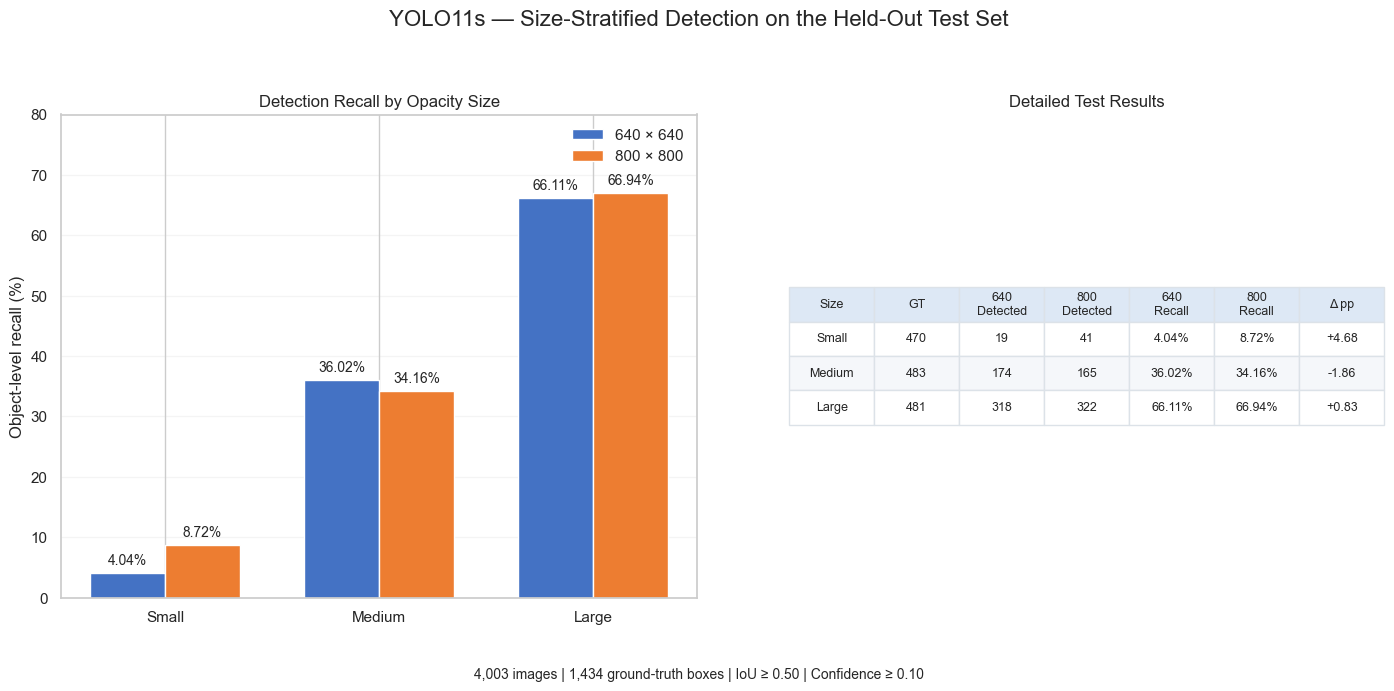

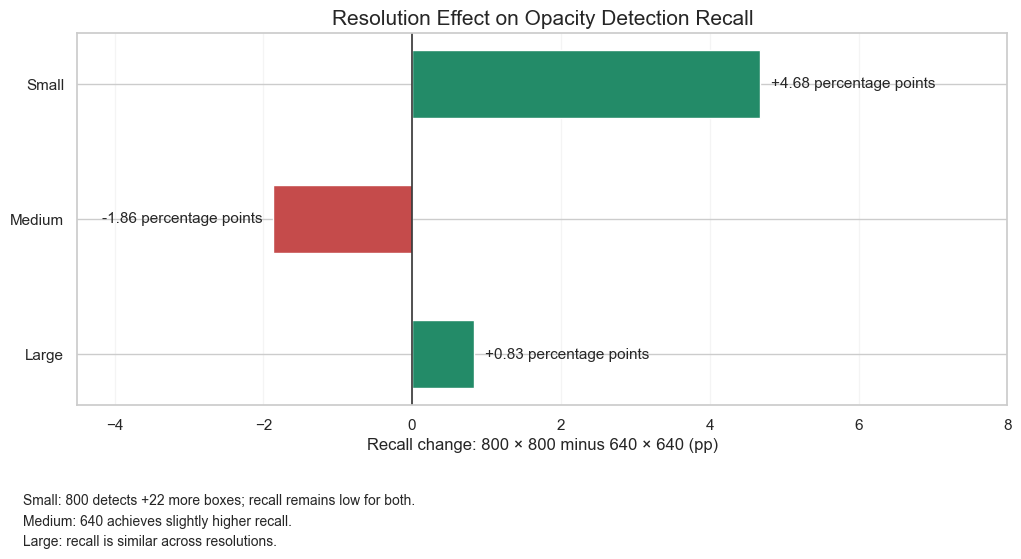

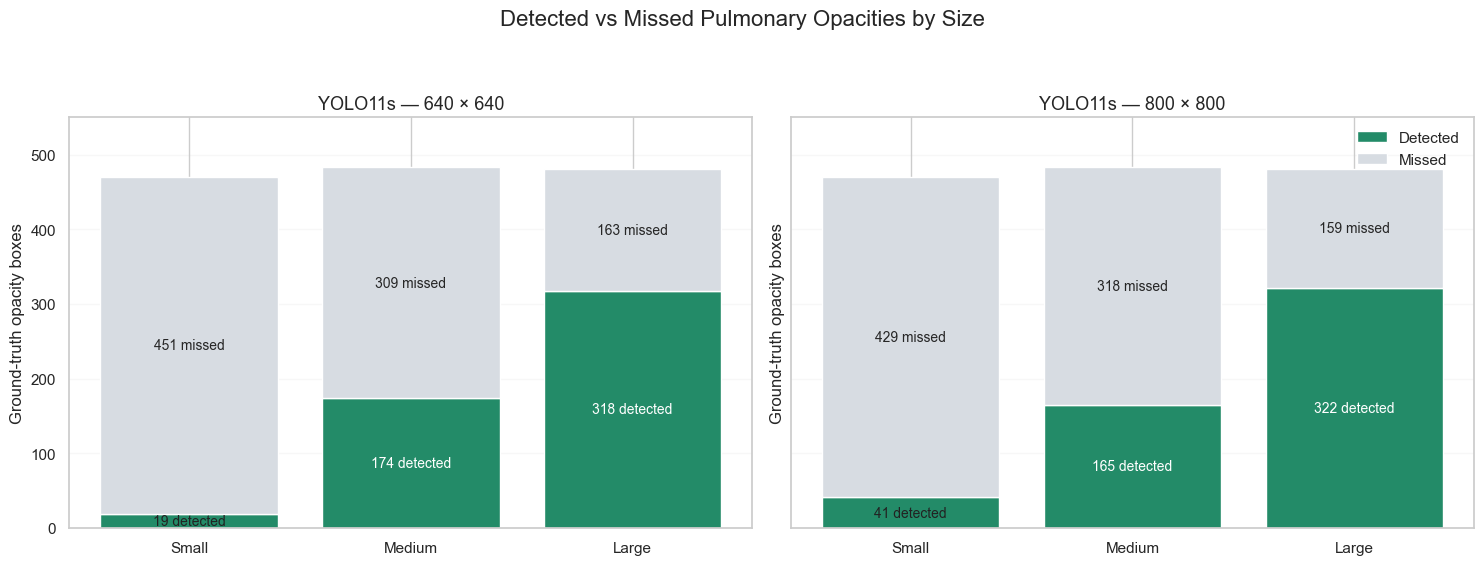


RESEARCH INTERPRETATION
Small opacities: 800 × 800 improves observed recall by +4.68 percentage points.
Medium opacities: recall difference = -1.86 percentage points.
Large opacities: recall difference = +0.83 percentage points.

Interpretation: Higher input resolution improves observed small-opacity recall at the fixed evaluation threshold, but does not consistently improve recall across all sizes.
Limitation: Small-opacity recall remains low for both models. Statistical uncertainty and false-positive differences are reported in Phase 6.3.3B.
Note: Size categories are based on training-derived normalized bounding-box area tertiles.

Saved research figures:
  /kaggle/working/rsna_pneumonia/results/figures/size_analysis/size_recall_comparison.png
  /kaggle/working/rsna_pneumonia/results/figures/size_analysis/size_recall_comparison.pdf
  /kaggle/working/rsna_pneumonia/results/figures/size_analysis/size_recall_interpretation.png
  /kaggle/working/rsna_pneumonia/results/figures/size_analy

In [46]:

# ============================================================
# Phase 6.3.2 — Size-Stratified Recall and Interpretation
# YOLO11s: 640 × 640 vs 800 × 800
# Saved-results visualization — NO MODEL INFERENCE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ------------------------------------------------------------
# 1. Load completed size-stratified evaluation
# ------------------------------------------------------------

analysis_dir = RESULTS_DIR / "size_analysis"
figure_dir = FIGURES_DIR / "size_analysis"

figure_dir.mkdir(parents=True, exist_ok=True)

results_path = analysis_dir / "size_stratified_recall.csv"

assert results_path.is_file(), (
    f"Missing saved results: {results_path}\n"
    "Restore the original CSV from your research archive. "
    "Model inference is intentionally disabled."
)

size_results = pd.read_csv(results_path)

CATEGORIES = ["small", "medium", "large"]
LABELS = ["Small", "Medium", "Large"]

required_columns = {
    "resolution",
    "size_category",
    "ground_truth_boxes",
    "detected_boxes",
    "recall_at_iou50_conf010",
}

assert required_columns.issubset(size_results.columns), (
    "Saved CSV is missing required columns."
)

assert len(size_results) == 6, (
    "Expected three size categories for each resolution."
)

assert set(size_results["resolution"]) == {640, 800}
assert set(size_results["size_category"]) == set(CATEGORIES)

assert not size_results.duplicated(
    ["resolution", "size_category"]
).any(), "Duplicate resolution/size records found."

print("=" * 65)
print("PHASE 6.3.2 — SIZE-STRATIFIED RECALL")
print("=" * 65)
print("Source: Previously completed test evaluation")
print("Model training: NOT PERFORMED")
print("Model inference: NOT PERFORMED")

# ------------------------------------------------------------
# 2. Prepare comparative results
# ------------------------------------------------------------

recall = size_results.pivot(
    index="size_category",
    columns="resolution",
    values="recall_at_iou50_conf010"
).loc[CATEGORIES, [640, 800]] * 100

detected = size_results.pivot(
    index="size_category",
    columns="resolution",
    values="detected_boxes"
).loc[CATEGORIES, [640, 800]]

gt_counts = size_results.pivot(
    index="size_category",
    columns="resolution",
    values="ground_truth_boxes"
).loc[CATEGORIES, [640, 800]]

# Lightweight integrity checks
assert (gt_counts[640] == gt_counts[800]).all()
assert gt_counts[640].sum() == 1434
assert (detected <= gt_counts).all().all()
assert (detected >= 0).all().all()

calculated_recall = detected / gt_counts * 100

assert np.allclose(
    recall.to_numpy(),
    calculated_recall.to_numpy(),
    atol=1e-6
), "Saved recall values disagree with detected/GT counts."

gt = gt_counts[640]
difference = recall[800] - recall[640]
missed = gt_counts - detected

print("\nDETAILED TEST RESULTS")
print(size_results.round(4).to_string(index=False))

summary = pd.DataFrame({
    "GT boxes": gt,
    "640 detected": detected[640],
    "800 detected": detected[800],
    "640 recall (%)": recall[640],
    "800 recall (%)": recall[800],
    "Difference (pp)": difference
})

summary_path = (
    analysis_dir / "size_recall_interpretation_summary.csv"
)

summary.to_csv(summary_path)

print("\nCOMPARATIVE SUMMARY")
print(summary.round(2).to_string())
print(f"\nSummary saved: {summary_path}")

# ------------------------------------------------------------
# 3. Figure styling
# ------------------------------------------------------------

BLUE = "#4472C4"
ORANGE = "#ED7D31"
GREEN = "#238B68"
RED = "#C54B4B"

# ------------------------------------------------------------
# 4. Figure 1 — Recall comparison and numerical table
# ------------------------------------------------------------

fig = plt.figure(figsize=(17, 7))

gs = GridSpec(
    1, 2,
    figure=fig,
    width_ratios=[1.2, 1.1],
    wspace=0.16
)

ax = fig.add_subplot(gs[0, 0])
ax_table = fig.add_subplot(gs[0, 1])

x = np.arange(3)
width = 0.35

bars640 = ax.bar(
    x - width / 2,
    recall[640],
    width,
    label="640 × 640",
    color=BLUE
)

bars800 = ax.bar(
    x + width / 2,
    recall[800],
    width,
    label="800 × 800",
    color=ORANGE
)

for bars in (bars640, bars800):
    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=4,
        fontsize=10
    )

ax.set_xticks(x, LABELS)
ax.set_ylim(0, 80)
ax.set_ylabel("Object-level recall (%)")

ax.set_title(
    "Detection Recall by Opacity Size",
    fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

table_rows = [
    [
        category.capitalize(),
        str(int(gt[category])),
        str(int(detected.loc[category, 640])),
        str(int(detected.loc[category, 800])),
        f"{recall.loc[category, 640]:.2f}%",
        f"{recall.loc[category, 800]:.2f}%",
        f"{difference[category]:+.2f}"
    ]
    for category in CATEGORIES
]

ax_table.axis("off")

ax_table.set_title(
    "Detailed Test Results",
    fontweight="bold"
)

table = ax_table.table(
    cellText=table_rows,
    colLabels=[
        "Size",
        "GT",
        "640\nDetected",
        "800\nDetected",
        "640\nRecall",
        "800\nRecall",
        "Δ pp"
    ],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.02, 2.3)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#DCE2E8")

    if r == 0:
        cell.set_facecolor("#DDE8F5")
        cell.set_text_props(weight="bold")

    elif r % 2 == 0:
        cell.set_facecolor("#F5F7FA")

fig.suptitle(
    "YOLO11s — Size-Stratified Detection on the Held-Out Test Set",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5,
    0.025,
    "4,003 images | 1,434 ground-truth boxes | "
    "IoU ≥ 0.50 | Confidence ≥ 0.10",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(top=0.83, bottom=0.14)

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"size_recall_comparison.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Figure 2 — Interpretation of resolution effects
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

values = difference.values

colors = [
    GREEN if value >= 0 else RED
    for value in values
]

bars = ax.barh(
    LABELS,
    values,
    color=colors,
    height=0.5
)

ax.axvline(
    0,
    color="#333333",
    linewidth=1.2
)

ax.invert_yaxis()

for bar, value in zip(bars, values):
    ax.annotate(
        f"{value:+.2f} percentage points",
        xy=(
            value,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(
            8 if value >= 0 else -8,
            0
        ),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(
    min(-4.5, values.min() - 2),
    max(8, values.max() + 2)
)

ax.set_xlabel(
    "Recall change: 800 × 800 minus 640 × 640 (pp)"
)

ax.set_title(
    "Resolution Effect on Opacity Detection Recall",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

interpretations = [
    (
        f"Small: 800 detects "
        f"{int(detected.loc['small', 800] - detected.loc['small', 640]):+d} "
        f"more boxes; recall remains low for both."
    ),
    (
        "Medium: 640 achieves slightly higher recall."
        if difference["medium"] < 0
        else "Medium: 800 achieves higher recall."
    ),
    (
        "Large: recall is similar across resolutions."
        if abs(difference["large"]) < 2
        else "Large: a larger recall difference is observed."
    )
]

fig.text(
    0.08,
    0.02,
    "\n".join(interpretations),
    fontsize=10,
    va="bottom",
    linespacing=1.6
)

fig.subplots_adjust(bottom=0.26)

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"size_recall_interpretation.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Figure 3 — Detected versus missed opacities
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharey=True
)

for ax, resolution in zip(axes, (640, 800)):

    found = detected[resolution].values
    not_found = missed[resolution].values

    ax.bar(
        LABELS,
        found,
        color=GREEN,
        label="Detected"
    )

    ax.bar(
        LABELS,
        not_found,
        bottom=found,
        color="#D7DCE2",
        label="Missed"
    )

    for i, (f, m) in enumerate(zip(found, not_found)):

        if f > 0:
            ax.text(
                i,
                f / 2,
                f"{f} detected",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
                color=(
                    "white" if f > 50
                    else "#222222"
                )
            )

        ax.text(
            i,
            f + m / 2,
            f"{m} missed",
            ha="center",
            va="center",
            fontsize=10
        )

    ax.set_title(
        f"YOLO11s — {resolution} × {resolution}",
        fontweight="bold",
        fontsize=13
    )

    ax.set_ylabel("Ground-truth opacity boxes")
    ax.set_ylim(0, 550)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

axes[1].legend(
    loc="upper right",
    frameon=False
)

fig.suptitle(
    "Detected vs Missed Pulmonary Opacities by Size",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0.04, 1, 0.93])

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"size_detection_outcomes.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Final research interpretation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RESEARCH INTERPRETATION")
print("=" * 65)

print(
    f"Small opacities: 800 × 800 improves observed recall by "
    f"{difference['small']:+.2f} percentage points."
)

print(
    f"Medium opacities: recall difference = "
    f"{difference['medium']:+.2f} percentage points."
)

print(
    f"Large opacities: recall difference = "
    f"{difference['large']:+.2f} percentage points."
)

print(
    "\nInterpretation: Higher input resolution improves observed "
    "small-opacity recall at the fixed evaluation threshold, "
    "but does not consistently improve recall across all sizes."
)

print(
    "Limitation: Small-opacity recall remains low for both "
    "models. Statistical uncertainty and false-positive "
    "differences are reported in Phase 6.3.3B."
)

print(
    "Note: Size categories are based on training-derived "
    "normalized bounding-box area tertiles."
)

# ------------------------------------------------------------
# 8. Saved outputs
# ------------------------------------------------------------

print("\nSaved research figures:")

for name in (
    "size_recall_comparison",
    "size_recall_interpretation",
    "size_detection_outcomes"
):
    for ext in ("png", "pdf"):
        path = figure_dir / f"{name}.{ext}"
        print(f"  {path}")

print(f"\nSaved summary: {summary_path}")

print("\nPHASE 6.3.2 — COMPLETED")
#print("Model training: NOT PERFORMED")
#print("Model inference: NOT PERFORMED")


In [47]:

# ============================================================
# Phase 6.3.3A — Per-Image Detection and False-Positive Records
# Completed evaluation — NO MODEL INFERENCE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

analysis_dir = RESULTS_DIR / "size_analysis"

records_path = (
    analysis_dir / "per_image_detection_records.csv"
)
recall_path = (
    analysis_dir / "size_stratified_recall.csv"
)

# ------------------------------------------------------------
# 1. Load previously completed evaluation records
# ------------------------------------------------------------

assert records_path.is_file(), (
    f"Missing per-image records: {records_path}\n"
    "Restore the CSV from your saved research archive. "
    "Do not rerun model inference merely to recreate this file."
)

per_image = pd.read_csv(
    records_path,
    dtype={"image_id": str}
)

required_columns = {
    "resolution", "image_id", "is_background",
    "gt_small", "gt_medium", "gt_large",
    "tp_small", "tp_medium", "tp_large",
    "predictions", "false_positives"
}

assert required_columns.issubset(per_image.columns), (
    "Missing required per-image record columns."
)

assert len(per_image) == 8006
assert set(per_image["resolution"]) == {640, 800}

assert not per_image.duplicated(
    ["resolution", "image_id"]
).any()

# ------------------------------------------------------------
# 2. Verify paired image records and detection counts
# ------------------------------------------------------------

ids_640 = set(
    per_image.loc[
        per_image["resolution"] == 640, "image_id"
    ]
)

ids_800 = set(
    per_image.loc[
        per_image["resolution"] == 800, "image_id"
    ]
)

assert len(ids_640) == 4003
assert ids_640 == ids_800

gt_columns = ["gt_small", "gt_medium", "gt_large"]
tp_columns = ["tp_small", "tp_medium", "tp_large"]

for resolution in (640, 800):

    subset = per_image[
        per_image["resolution"] == resolution
    ]

    assert subset[gt_columns].sum().sum() == 1434

    for category in ("small", "medium", "large"):
        assert (
            subset[f"tp_{category}"]
            <= subset[f"gt_{category}"]
        ).all()

    assert (
        subset["predictions"].sum()
        ==
        subset[tp_columns].sum().sum()
        + subset["false_positives"].sum()
    )

# ------------------------------------------------------------
# 3. Cross-check size-stratified recall results
# ------------------------------------------------------------

assert recall_path.is_file(), (
    f"Missing size-recall results: {recall_path}"
)

previous = pd.read_csv(recall_path)

for resolution in (640, 800):

    subset = per_image[
        per_image["resolution"] == resolution
    ]

    for category in ("small", "medium", "large"):

        matching_rows = previous[
            (previous["resolution"] == resolution)
            & (previous["size_category"] == category)
        ]

        assert len(matching_rows) == 1

        old = matching_rows.iloc[0]

        assert (
            subset[f"gt_{category}"].sum()
            == old["ground_truth_boxes"]
        )

        assert (
            subset[f"tp_{category}"].sum()
            == old["detected_boxes"]
        )

print("Per-image records and size-recall results: VERIFIED")

# ------------------------------------------------------------
# 4. Summarize detection and false-positive burden
# ------------------------------------------------------------

summary = per_image.groupby("resolution").agg(
    images=("image_id", "count"),
    background_images=("is_background", "sum"),
    total_predictions=("predictions", "sum"),
    false_positives=("false_positives", "sum")
)

summary["matched_detections"] = (
    summary["total_predictions"]
    - summary["false_positives"]
)

summary["fp_per_image"] = (
    summary["false_positives"] / summary["images"]
)

print("\n" + "=" * 65)
print("PHASE 6.3.3A — PER-IMAGE DETECTION ANALYSIS")
print("=" * 65)

print(summary.round(4).to_string())

print(f"\nSource: {records_path}")
print("Model training: NOT PERFORMED")
print("Model inference: NOT PERFORMED")
print("Original per-image CSV: PRESERVED")


Per-image records and size-recall results: VERIFIED

PHASE 6.3.3A — PER-IMAGE DETECTION ANALYSIS
            images  background_images  total_predictions  false_positives  matched_detections  fp_per_image
resolution                                                                                                 
640           4003               3102               1308              797                 511        0.1991
800           4003               3102               1427              899                 528        0.2246

Source: /kaggle/working/rsna_pneumonia/results/size_analysis/per_image_detection_records.csv
Model training: NOT PERFORMED
Model inference: NOT PERFORMED
Original per-image CSV: PRESERVED


Loaded original paired bootstrap results.
Bootstrap recalculation: NOT PERFORMED
Saved statistics and image-level records: VERIFIED


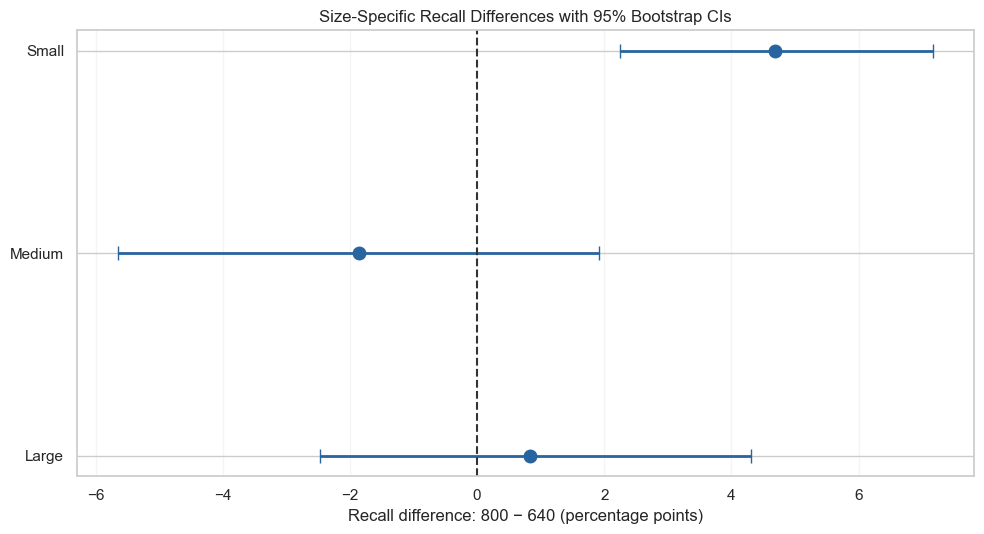

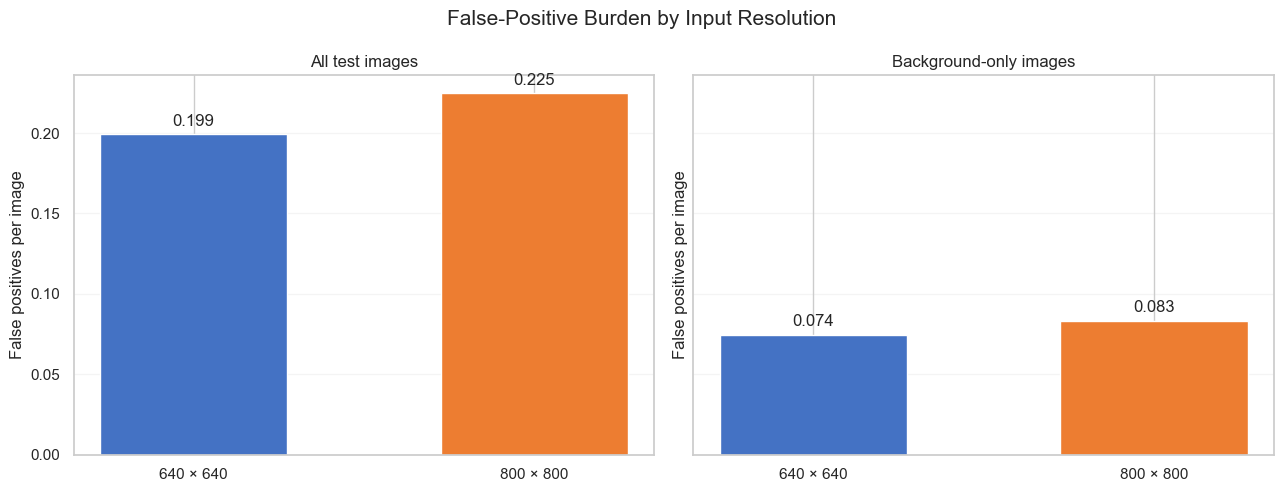

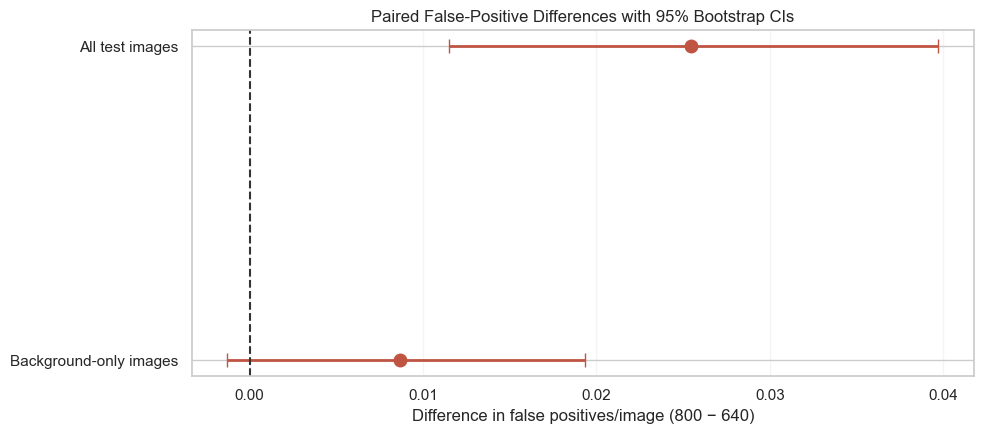


PAIRED BOOTSTRAP — SIZE-SPECIFIC RECALL
  size  difference_pp  ci_low_pp  ci_high_pp
 Small          4.681      2.242       7.173
Medium         -1.863     -5.645       1.911
 Large          0.832     -2.474       4.302

PAIRED BOOTSTRAP — FALSE POSITIVES PER IMAGE
            population  images  fp_per_image_640  fp_per_image_800  difference  ci_low  ci_high
       All test images    4003            0.1991            0.2246      0.0255  0.0115   0.0397
Background-only images    3102            0.0745            0.0832      0.0087 -0.0013   0.0193

RESEARCH INTERPRETATION
Small: +4.68 pp [+2.24, +7.17] — 95% CI entirely above zero
Medium: -1.86 pp [-5.65, +1.91] — 95% CI includes zero
Large: +0.83 pp [-2.47, +4.30] — 95% CI includes zero

Interpretation: The 800 × 800 model improves small-opacity recall, but also increases the overall false-positive burden.
Limitation: Confidence intervals reflect paired test-image resampling, not variation across independent training runs.

PHASE 6.3

In [49]:

# ============================================================
# Phase 6.3.3B — Paired Bootstrap and FP Visualization
# YOLO11s: 640 × 640 vs 800 × 800
# Saved-results-first reproducible analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration and saved research artifacts
# ------------------------------------------------------------

analysis_dir = RESULTS_DIR / "size_analysis"
figure_dir = FIGURES_DIR / "size_analysis"
figure_dir.mkdir(parents=True, exist_ok=True)

records_path = analysis_dir / "per_image_detection_records.csv"
recall_path = analysis_dir / "paired_bootstrap_recall_ci.csv"
fp_path = analysis_dir / "paired_bootstrap_fp_ci.csv"

# False: load completed bootstrap results (recommended)
# True: recompute bootstrap from saved per-image records
RUN_BOOTSTRAP = False

SEED = 42
N_BOOT = 3000

sizes = ["small", "medium", "large"]
colors = ["#4472C4", "#ED7D31"]

assert records_path.is_file(), (
    f"Missing per-image records: {records_path}. "
    "Restore the CSV from your research archive."
)

df = pd.read_csv(records_path, dtype={"image_id": str})

# ------------------------------------------------------------
# 2. Pair and validate image-level records
# ------------------------------------------------------------

a = (
    df[df["resolution"] == 640]
    .set_index("image_id")
    .sort_index()
)

b = (
    df[df["resolution"] == 800]
    .set_index("image_id")
    .sort_index()
)

assert len(a) == len(b) == 4003
assert a.index.is_unique and b.index.is_unique
assert a.index.equals(b.index)
assert (a["is_background"] == b["is_background"]).all()

for size in sizes:
    assert (
        a[f"gt_{size}"] == b[f"gt_{size}"]
    ).all(), f"Ground-truth mismatch: {size}"

background = a["is_background"] == 1

# ------------------------------------------------------------
# 3. Paired image-level bootstrap method
# ------------------------------------------------------------

def paired_bootstrap_difference(
    x640, x800, rng, denominator=None
):
    """
    Paired bootstrap using image-level resampling.

    With denominator:
        Difference in ratio-of-sums recall (800 - 640).

    Without denominator:
        Difference in mean false positives per image.

    Returns observed difference and percentile 95% CI.
    """

    x640 = np.asarray(x640, dtype=float)
    x800 = np.asarray(x800, dtype=float)

    assert len(x640) == len(x800)
    assert len(x640) > 0

    if denominator is not None:
        denominator = np.asarray(denominator, dtype=float)
        assert len(denominator) == len(x640)
        assert denominator.sum() > 0

        observed = (
            x800.sum() - x640.sum()
        ) / denominator.sum()
    else:
        observed = (x800 - x640).mean()

    samples = np.empty(N_BOOT, dtype=float)

    for i in range(N_BOOT):
        idx = rng.integers(
            0, len(x640), size=len(x640)
        )

        if denominator is None:
            samples[i] = (
                x800[idx] - x640[idx]
            ).mean()
        else:
            total = denominator[idx].sum()

            samples[i] = (
                (
                    x800[idx].sum()
                    - x640[idx].sum()
                ) / total
                if total > 0 else np.nan
            )

    ci_low, ci_high = np.nanpercentile(
        samples, [2.5, 97.5]
    )

    return observed, ci_low, ci_high

# ------------------------------------------------------------
# 4. Recompute or load completed bootstrap results
# ------------------------------------------------------------

if RUN_BOOTSTRAP:

    # Preserve existing research evidence
    assert not recall_path.exists(), (
        f"Existing bootstrap results found: {recall_path}. "
        "Use RUN_BOOTSTRAP=False to preserve them."
    )
    assert not fp_path.exists(), (
        f"Existing bootstrap results found: {fp_path}. "
        "Use RUN_BOOTSTRAP=False to preserve them."
    )

    rng = np.random.default_rng(SEED)

    recall_rows = []

    for size in sizes:
        observed, low, high = paired_bootstrap_difference(
            a[f"tp_{size}"],
            b[f"tp_{size}"],
            rng,
            denominator=a[f"gt_{size}"]
        )

        recall_rows.append({
            "size": size.capitalize(),
            "difference_pp": observed * 100,
            "ci_low_pp": low * 100,
            "ci_high_pp": high * 100
        })

    recall_ci = pd.DataFrame(recall_rows)

    fp_observed, fp_low, fp_high = (
        paired_bootstrap_difference(
            a["false_positives"],
            b["false_positives"],
            rng
        )
    )

    bg_640 = a.loc[background, "false_positives"]
    bg_800 = b.loc[background, "false_positives"]

    bg_observed, bg_low, bg_high = (
        paired_bootstrap_difference(
            bg_640, bg_800, rng
        )
    )

    fp_summary = pd.DataFrame([
        {
            "population": "All test images",
            "images": len(a),
            "fp_per_image_640": a["false_positives"].mean(),
            "fp_per_image_800": b["false_positives"].mean(),
            "difference": fp_observed,
            "ci_low": fp_low,
            "ci_high": fp_high
        },
        {
            "population": "Background-only images",
            "images": int(background.sum()),
            "fp_per_image_640": bg_640.mean(),
            "fp_per_image_800": bg_800.mean(),
            "difference": bg_observed,
            "ci_low": bg_low,
            "ci_high": bg_high
        }
    ])

    recall_ci.to_csv(recall_path, index=False)
    fp_summary.to_csv(fp_path, index=False)

    print("Bootstrap recomputed from saved image-level records.")

else:

    assert recall_path.is_file(), (
        f"Missing saved bootstrap results: {recall_path}. "
        "Restore the original CSV from your archive."
    )

    assert fp_path.is_file(), (
        f"Missing saved false-positive results: {fp_path}. "
        "Restore the original CSV from your archive."
    )

    recall_ci = pd.read_csv(recall_path)
    fp_summary = pd.read_csv(fp_path)

    print("Loaded original paired bootstrap results.")
    print("Bootstrap recalculation: NOT PERFORMED")

# ------------------------------------------------------------
# 5. Verify saved results against image-level records
# ------------------------------------------------------------

assert set(recall_ci["size"]) == {
    "Small", "Medium", "Large"
}

assert len(recall_ci) == 3

assert set(fp_summary["population"]) == {
    "All test images",
    "Background-only images"
}

assert len(fp_summary) == 2

recall_ci = (
    recall_ci.set_index("size")
    .loc[["Small", "Medium", "Large"]]
    .reset_index()
)

fp_summary = (
    fp_summary.set_index("population")
    .loc[
        ["All test images", "Background-only images"]
    ]
    .reset_index()
)

# Confirm observed recall differences
for size in sizes:

    gt_total = a[f"gt_{size}"].sum()

    expected_difference = (
        b[f"tp_{size}"].sum()
        - a[f"tp_{size}"].sum()
    ) / gt_total * 100

    saved_difference = recall_ci.loc[
        recall_ci["size"] == size.capitalize(),
        "difference_pp"
    ].iloc[0]

    assert np.isclose(
        expected_difference,
        saved_difference,
        atol=1e-6
    ), f"Recall difference mismatch: {size}"

# Confirm observed false-positive statistics
for _, row in fp_summary.iterrows():

    if row["population"] == "All test images":
        group640, group800 = a, b
    else:
        group640 = a.loc[background]
        group800 = b.loc[background]

    mean640 = group640["false_positives"].mean()
    mean800 = group800["false_positives"].mean()

    assert int(row["images"]) == len(group640)

    assert np.isclose(
        row["fp_per_image_640"], mean640, atol=1e-6
    )

    assert np.isclose(
        row["fp_per_image_800"], mean800, atol=1e-6
    )

    assert np.isclose(
        row["difference"],
        mean800 - mean640,
        atol=1e-6
    )

print("Saved statistics and image-level records: VERIFIED")

# ------------------------------------------------------------
# 6. Figure 1 — Recall differences with 95% bootstrap CIs
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

y = np.arange(len(sizes))

values = recall_ci["difference_pp"].to_numpy()
lower = values - recall_ci["ci_low_pp"].to_numpy()
upper = recall_ci["ci_high_pp"].to_numpy() - values

ax.errorbar(
    values,
    y,
    xerr=np.vstack([lower, upper]),
    fmt="o",
    markersize=9,
    capsize=5,
    linewidth=2,
    color="#2864A0",
    ecolor="#2864A0"
)

ax.axvline(
    0, color="#333333", linestyle="--"
)

ax.set_yticks(
    y, [size.capitalize() for size in sizes]
)

ax.invert_yaxis()
ax.set_xlabel(
    "Recall difference: 800 − 640 (percentage points)"
)
ax.set_title(
    "Size-Specific Recall Differences with 95% Bootstrap CIs",
    fontweight="bold"
)
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"recall_bootstrap_ci.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Figure 2 — False-positive comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True
)

groups = [
    ("All test images", a, b),
    (
        "Background-only images",
        a.loc[background],
        b.loc[background]
    )
]

for ax, (title, group640, group800) in zip(
    axes, groups
):

    values = [
        group640["false_positives"].mean(),
        group800["false_positives"].mean()
    ]

    bars = ax.bar(
        ["640 × 640", "800 × 800"],
        values,
        color=colors,
        width=0.55
    )

    ax.bar_label(
        bars, fmt="%.3f", padding=4
    )

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("False positives per image")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "False-Positive Burden by Input Resolution",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"false_positive_comparison.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. Figure 3 — Paired FP differences with 95% CIs
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.5))

labels = fp_summary["population"].tolist()
diff = fp_summary["difference"].to_numpy()

low = diff - fp_summary["ci_low"].to_numpy()
high = fp_summary["ci_high"].to_numpy() - diff

ax.errorbar(
    diff,
    np.arange(len(labels)),
    xerr=np.vstack([low, high]),
    fmt="o",
    capsize=5,
    markersize=9,
    linewidth=2,
    color="#C05443"
)

ax.axvline(
    0, color="#333333", linestyle="--"
)

ax.set_yticks(
    np.arange(len(labels)), labels
)

ax.invert_yaxis()
ax.set_xlabel(
    "Difference in false positives/image (800 − 640)"
)
ax.set_title(
    "Paired False-Positive Differences with 95% Bootstrap CIs",
    fontweight="bold"
)
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        figure_dir / f"false_positive_bootstrap_ci.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Numerical research interpretation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PAIRED BOOTSTRAP — SIZE-SPECIFIC RECALL")
print("=" * 65)

print(recall_ci.round(3).to_string(index=False))

print("\n" + "=" * 65)
print("PAIRED BOOTSTRAP — FALSE POSITIVES PER IMAGE")
print("=" * 65)

print(fp_summary.round(4).to_string(index=False))

print("\nRESEARCH INTERPRETATION")

for _, row in recall_ci.iterrows():

    if row["ci_low_pp"] > 0:
        interpretation = "95% CI entirely above zero"
    elif row["ci_high_pp"] < 0:
        interpretation = "95% CI entirely below zero"
    else:
        interpretation = "95% CI includes zero"

    print(
        f"{row['size']}: "
        f"{row['difference_pp']:+.2f} pp "
        f"[{row['ci_low_pp']:+.2f}, "
        f"{row['ci_high_pp']:+.2f}] — "
        f"{interpretation}"
    )

print(
    "\nInterpretation: The 800 × 800 model improves "
    "small-opacity recall, but also increases the "
    "overall false-positive burden."
)

print(
    "Limitation: Confidence intervals reflect paired "
    "test-image resampling, not variation across "
    "independent training runs."
)

print("\nPHASE 6.3.3B — COMPLETED")


Loaded previously completed GPU benchmark.
GPU benchmarking: NOT PERFORMED

PHASE 6.4.1 — COMPUTATIONAL EFFICIENCY
            batch_size_gpu_forward  batch_size_pipeline  benchmark_images  gpu_forward_ms_per_image  gpu_forward_throughput_fps  peak_gpu_memory_mib  pipeline_ms_per_image  pipeline_throughput_fps
resolution                                                                                                                                                                                          
640                              8                    1               256                     8.493                     117.740             5564.530                 31.577                   31.669
800                              8                    1               256                    13.858                      72.163             5810.678                 34.188                   29.250


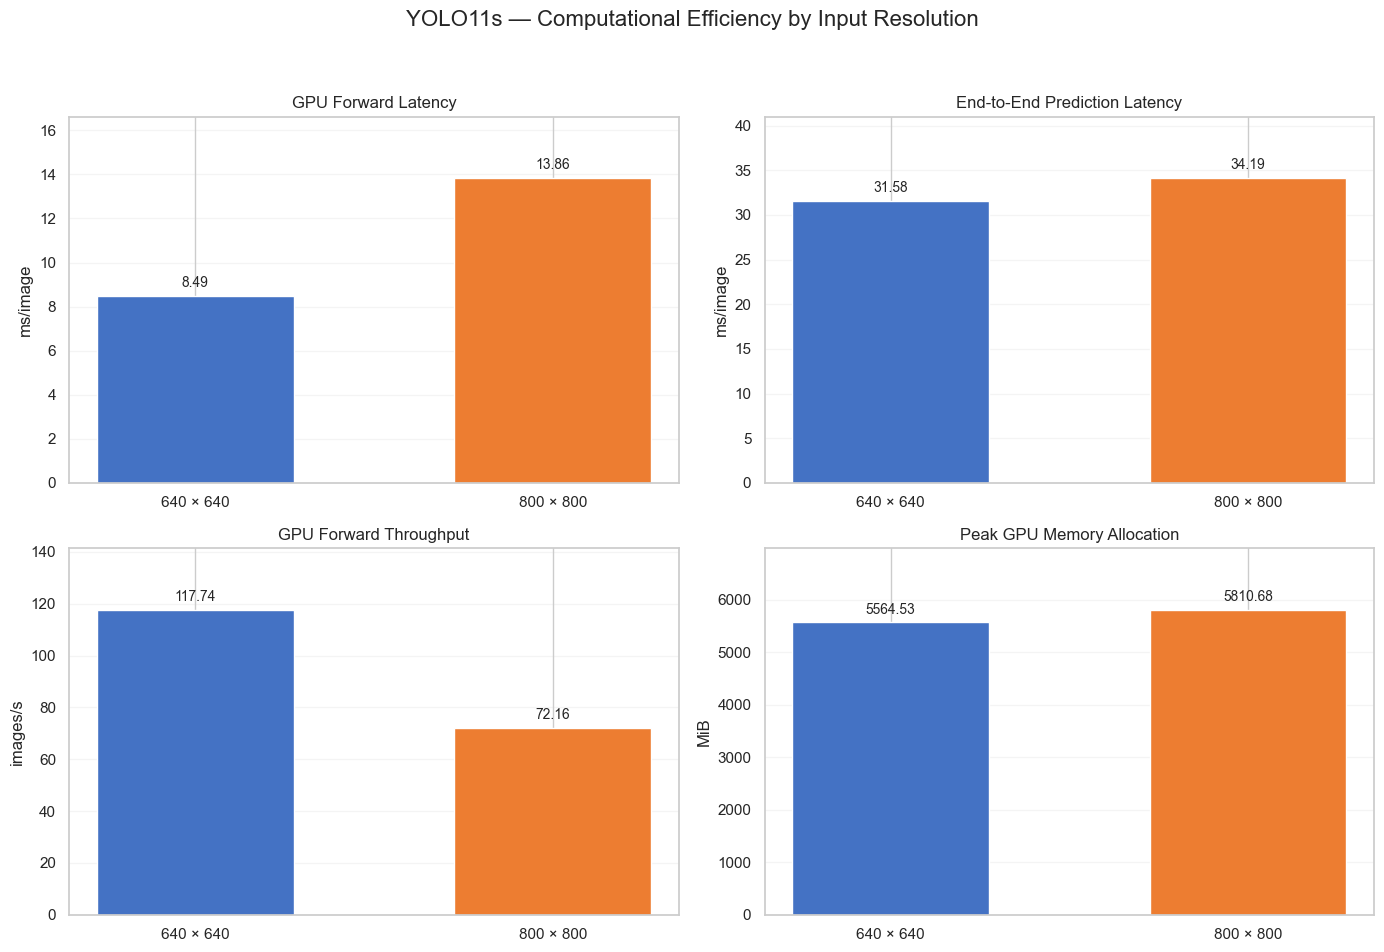


COMPUTATIONAL TRADE-OFF
GPU forward latency change: +63.16%
End-to-end latency change: +8.27%
Peak GPU memory change: +4.42%

Saved benchmark artifacts:
Results: /kaggle/working/rsna_pneumonia/results/efficiency_benchmark/efficiency_comparison.csv
Configuration: /kaggle/working/rsna_pneumonia/results/efficiency_benchmark/benchmark_config.json
Benchmark image IDs: /kaggle/working/rsna_pneumonia/results/efficiency_benchmark/benchmark_image_ids.csv
Figure PNG: /kaggle/working/rsna_pneumonia/results/figures/efficiency_benchmark/efficiency_comparison.png
Figure PDF: /kaggle/working/rsna_pneumonia/results/figures/efficiency_benchmark/efficiency_comparison.pdf

PHASE 6.4.1 — COMPLETED


In [50]:

# ============================================================
# Phase 6.4.1 — Standardized Computational Efficiency Benchmark
# YOLO11s: 640 × 640 vs 800 × 800
# Saved-results-first, reproducible benchmark
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

benchmark_dir = RESULTS_DIR / "efficiency_benchmark"
figure_dir = FIGURES_DIR / "efficiency_benchmark"

benchmark_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

csv_path = benchmark_dir / "efficiency_comparison.csv"
config_path = benchmark_dir / "benchmark_config.json"
image_ids_path = benchmark_dir / "benchmark_image_ids.csv"

# False: load completed benchmark results (recommended).
# True: rerun GPU benchmark only when explicitly required.
RUN_BENCHMARK = False

BATCH_SIZE = 8
WARMUP_BATCHES = 10
BENCHMARK_IMAGES = 256
CONF_THRESHOLD = 0.10
NMS_IOU = 0.70
SEED = 42

# ------------------------------------------------------------
# 2. Run benchmark or reuse saved results
# ------------------------------------------------------------

if RUN_BENCHMARK:

    import gc
    import time
    import torch
    from ultralytics import YOLO

    assert torch.cuda.is_available(), (
        "CUDA GPU is required to rerun this benchmark."
    )

    assert BENCHMARK_IMAGES % BATCH_SIZE == 0

    # Protect previously completed research evidence.
    for path in (csv_path, config_path, image_ids_path):
        assert not path.exists(), (
            f"Existing benchmark artifact: {path}\n"
            "Use RUN_BENCHMARK=False to preserve the "
            "original research results."
        )

    DEVICE = torch.device("cuda:0")

    test_images_dir = YOLO_ROOT / "images" / "test"
    all_images = sorted(test_images_dir.glob("*.png"))

    assert len(all_images) == 4003

    # Deterministic shared test-image subset.
    rng = np.random.default_rng(SEED)

    selected_indices = np.sort(
        rng.choice(
            len(all_images),
            size=BENCHMARK_IMAGES,
            replace=False
        )
    )

    selected_images = [
        all_images[i] for i in selected_indices
    ]

    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Benchmark images: {len(selected_images)}")
    print(f"GPU forward batch size: {BATCH_SIZE}")
    print("Pipeline batch size: 1")
    print(f"Warm-up iterations: {WARMUP_BATCHES}")

    # --------------------------------------------------------
    # 2A. Synthetic GPU forward-pass benchmark
    # --------------------------------------------------------

    def benchmark_gpu_forward(model, resolution):

        batch = torch.zeros(
            (BATCH_SIZE, 3, resolution, resolution),
            device=DEVICE,
            dtype=torch.float32
        )

        model.model.to(DEVICE).eval()

        with torch.inference_mode():

            for _ in range(WARMUP_BATCHES):
                _ = model.model(batch)

            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

            timings = []

            for _ in range(
                BENCHMARK_IMAGES // BATCH_SIZE
            ):

                torch.cuda.synchronize()
                start = time.perf_counter()

                _ = model.model(batch)

                torch.cuda.synchronize()

                timings.append(
                    time.perf_counter() - start
                )

            peak_memory_mib = (
                torch.cuda.max_memory_allocated()
                / 1024**2
            )

        timings = np.asarray(timings)

        return {
            "gpu_forward_ms_per_image": float(
                timings.mean() * 1000 / BATCH_SIZE
            ),
            "gpu_forward_throughput_fps": float(
                BATCH_SIZE / timings.mean()
            ),
            "peak_gpu_memory_mib": float(
                peak_memory_mib
            )
        }

    # --------------------------------------------------------
    # 2B. End-to-end prediction benchmark
    # --------------------------------------------------------

    def benchmark_pipeline(model, resolution):

        timings = []

        # Warm up the complete prediction pipeline.
        for path in selected_images[:WARMUP_BATCHES]:

            _ = model.predict(
                source=str(path),
                imgsz=resolution,
                conf=CONF_THRESHOLD,
                iou=NMS_IOU,
                device=0,
                verbose=False,
                save=False
            )

        torch.cuda.synchronize()

        # Individual PNG files avoid list-source OOM.
        for path in selected_images:

            torch.cuda.synchronize()
            start = time.perf_counter()

            _ = model.predict(
                source=str(path),
                imgsz=resolution,
                conf=CONF_THRESHOLD,
                iou=NMS_IOU,
                device=0,
                verbose=False,
                save=False
            )

            torch.cuda.synchronize()

            timings.append(
                time.perf_counter() - start
            )

        timings = np.asarray(timings)

        return {
            "pipeline_ms_per_image": float(
                timings.mean() * 1000
            ),
            "pipeline_throughput_fps": float(
                1.0 / timings.mean()
            )
        }

    # --------------------------------------------------------
    # 2C. Benchmark both trained checkpoints
    # --------------------------------------------------------

    rows = []

    for resolution in (640, 800):

        assert BEST_MODELS[resolution].is_file(), (
            f"Missing checkpoint: "
            f"{BEST_MODELS[resolution]}"
        )

        print(
            f"\nBenchmarking YOLO11s "
            f"at {resolution} × {resolution}..."
        )

        gc.collect()
        torch.cuda.empty_cache()

        model = YOLO(str(BEST_MODELS[resolution]))

        gpu_metrics = benchmark_gpu_forward(
            model, resolution
        )

        pipeline_metrics = benchmark_pipeline(
            model, resolution
        )

        row = {
            "resolution": resolution,
            "batch_size_gpu_forward": BATCH_SIZE,
            "batch_size_pipeline": 1,
            "benchmark_images": BENCHMARK_IMAGES,
            **gpu_metrics,
            **pipeline_metrics
        }

        rows.append(row)

        print(
            f"GPU forward: "
            f"{row['gpu_forward_ms_per_image']:.2f} "
            "ms/image"
        )

        print(
            f"Pipeline: "
            f"{row['pipeline_ms_per_image']:.2f} "
            "ms/image"
        )

        print(
            f"Peak GPU memory: "
            f"{row['peak_gpu_memory_mib']:.1f} MiB"
        )

        del model
        gc.collect()
        torch.cuda.empty_cache()

    benchmark_df = (
        pd.DataFrame(rows)
        .set_index("resolution")
    )

    # Save only after successful benchmarking.
    benchmark_df.to_csv(csv_path)

    pd.DataFrame({
        "image_id": [
            path.stem for path in selected_images
        ]
    }).to_csv(image_ids_path, index=False)

    with open(config_path, "w") as f:
        json.dump(
            {
                "gpu": torch.cuda.get_device_name(0),
                "batch_size_gpu_forward": BATCH_SIZE,
                "batch_size_pipeline": 1,
                "warmup_batches": WARMUP_BATCHES,
                "benchmark_images": BENCHMARK_IMAGES,
                "precision": "FP32",
                "synthetic_gpu_forward": True,
                "pipeline_source": "individual PNG files",
                "seed": SEED
            },
            f,
            indent=4
        )

    print("\nNew benchmark results generated.")

else:

    # --------------------------------------------------------
    # Load original completed benchmark results
    # --------------------------------------------------------

    assert csv_path.is_file(), (
        f"Missing saved benchmark: {csv_path}\n"
        "Restore efficiency_comparison.csv from your "
        "research archive. Do not rerun GPU benchmarking "
        "merely to recreate this file."
    )

    benchmark_df = pd.read_csv(
        csv_path,
        index_col="resolution"
    )

    print("Loaded previously completed GPU benchmark.")
    print("GPU benchmarking: NOT PERFORMED")

# ------------------------------------------------------------
# 3. Validate completed benchmark results
# ------------------------------------------------------------

required_columns = {
    "batch_size_gpu_forward",
    "batch_size_pipeline",
    "benchmark_images",
    "gpu_forward_ms_per_image",
    "gpu_forward_throughput_fps",
    "peak_gpu_memory_mib",
    "pipeline_ms_per_image",
    "pipeline_throughput_fps"
}

assert required_columns.issubset(
    benchmark_df.columns
), "Benchmark CSV is missing required columns."

assert set(benchmark_df.index) == {640, 800}
assert len(benchmark_df) == 2

benchmark_df = benchmark_df.loc[[640, 800]]

assert (
    benchmark_df["batch_size_gpu_forward"] == 8
).all()

assert (
    benchmark_df["batch_size_pipeline"] == 1
).all()

assert (
    benchmark_df["benchmark_images"] == 256
).all()

metric_columns = [
    "gpu_forward_ms_per_image",
    "gpu_forward_throughput_fps",
    "peak_gpu_memory_mib",
    "pipeline_ms_per_image",
    "pipeline_throughput_fps"
]

assert np.isfinite(
    benchmark_df[metric_columns].to_numpy()
).all()

assert (
    benchmark_df[metric_columns] > 0
).all().all()

print("\n" + "=" * 70)
print("PHASE 6.4.1 — COMPUTATIONAL EFFICIENCY")
print("=" * 70)

print(benchmark_df.round(3).to_string())

# ------------------------------------------------------------
# 4. Visualization — 2 × 2 comparison
# ------------------------------------------------------------

metrics = [
    (
        "gpu_forward_ms_per_image",
        "GPU Forward Latency",
        "ms/image"
    ),
    (
        "pipeline_ms_per_image",
        "End-to-End Prediction Latency",
        "ms/image"
    ),
    (
        "gpu_forward_throughput_fps",
        "GPU Forward Throughput",
        "images/s"
    ),
    (
        "peak_gpu_memory_mib",
        "Peak GPU Memory Allocation",
        "MiB"
    )
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

colors = ["#4472C4", "#ED7D31"]

for ax, (column, title, unit) in zip(
    axes.flat, metrics
):

    values = benchmark_df.loc[
        [640, 800], column
    ].to_numpy()

    bars = ax.bar(
        ["640 × 640", "800 × 800"],
        values,
        color=colors,
        width=0.55
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(unit)
    ax.set_ylim(0, max(values) * 1.2)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "YOLO11s — Computational Efficiency by Input Resolution",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0.03, 1, 0.95])

for ext in ("png", "pdf"):

    fig.savefig(
        figure_dir / f"efficiency_comparison.{ext}",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Computational trade-off
# ------------------------------------------------------------

gpu_latency_change = (
    benchmark_df.loc[
        800, "gpu_forward_ms_per_image"
    ]
    / benchmark_df.loc[
        640, "gpu_forward_ms_per_image"
    ]
    - 1
) * 100

pipeline_latency_change = (
    benchmark_df.loc[
        800, "pipeline_ms_per_image"
    ]
    / benchmark_df.loc[
        640, "pipeline_ms_per_image"
    ]
    - 1
) * 100

memory_change = (
    benchmark_df.loc[
        800, "peak_gpu_memory_mib"
    ]
    / benchmark_df.loc[
        640, "peak_gpu_memory_mib"
    ]
    - 1
) * 100

print("\n" + "=" * 70)
print("COMPUTATIONAL TRADE-OFF")
print("=" * 70)

print(
    f"GPU forward latency change: "
    f"{gpu_latency_change:+.2f}%"
)

print(
    f"End-to-end latency change: "
    f"{pipeline_latency_change:+.2f}%"
)

print(
    f"Peak GPU memory change: "
    f"{memory_change:+.2f}%"
)

print("\nSaved benchmark artifacts:")
print(f"Results: {csv_path}")

if config_path.is_file():
    print(f"Configuration: {config_path}")

if image_ids_path.is_file():
    print(f"Benchmark image IDs: {image_ids_path}")

print(
    f"Figure PNG: "
    f"{figure_dir / 'efficiency_comparison.png'}"
)

print(
    f"Figure PDF: "
    f"{figure_dir / 'efficiency_comparison.pdf'}"
)

print("\nPHASE 6.4.1 — COMPLETED")


Completed research results loaded successfully.


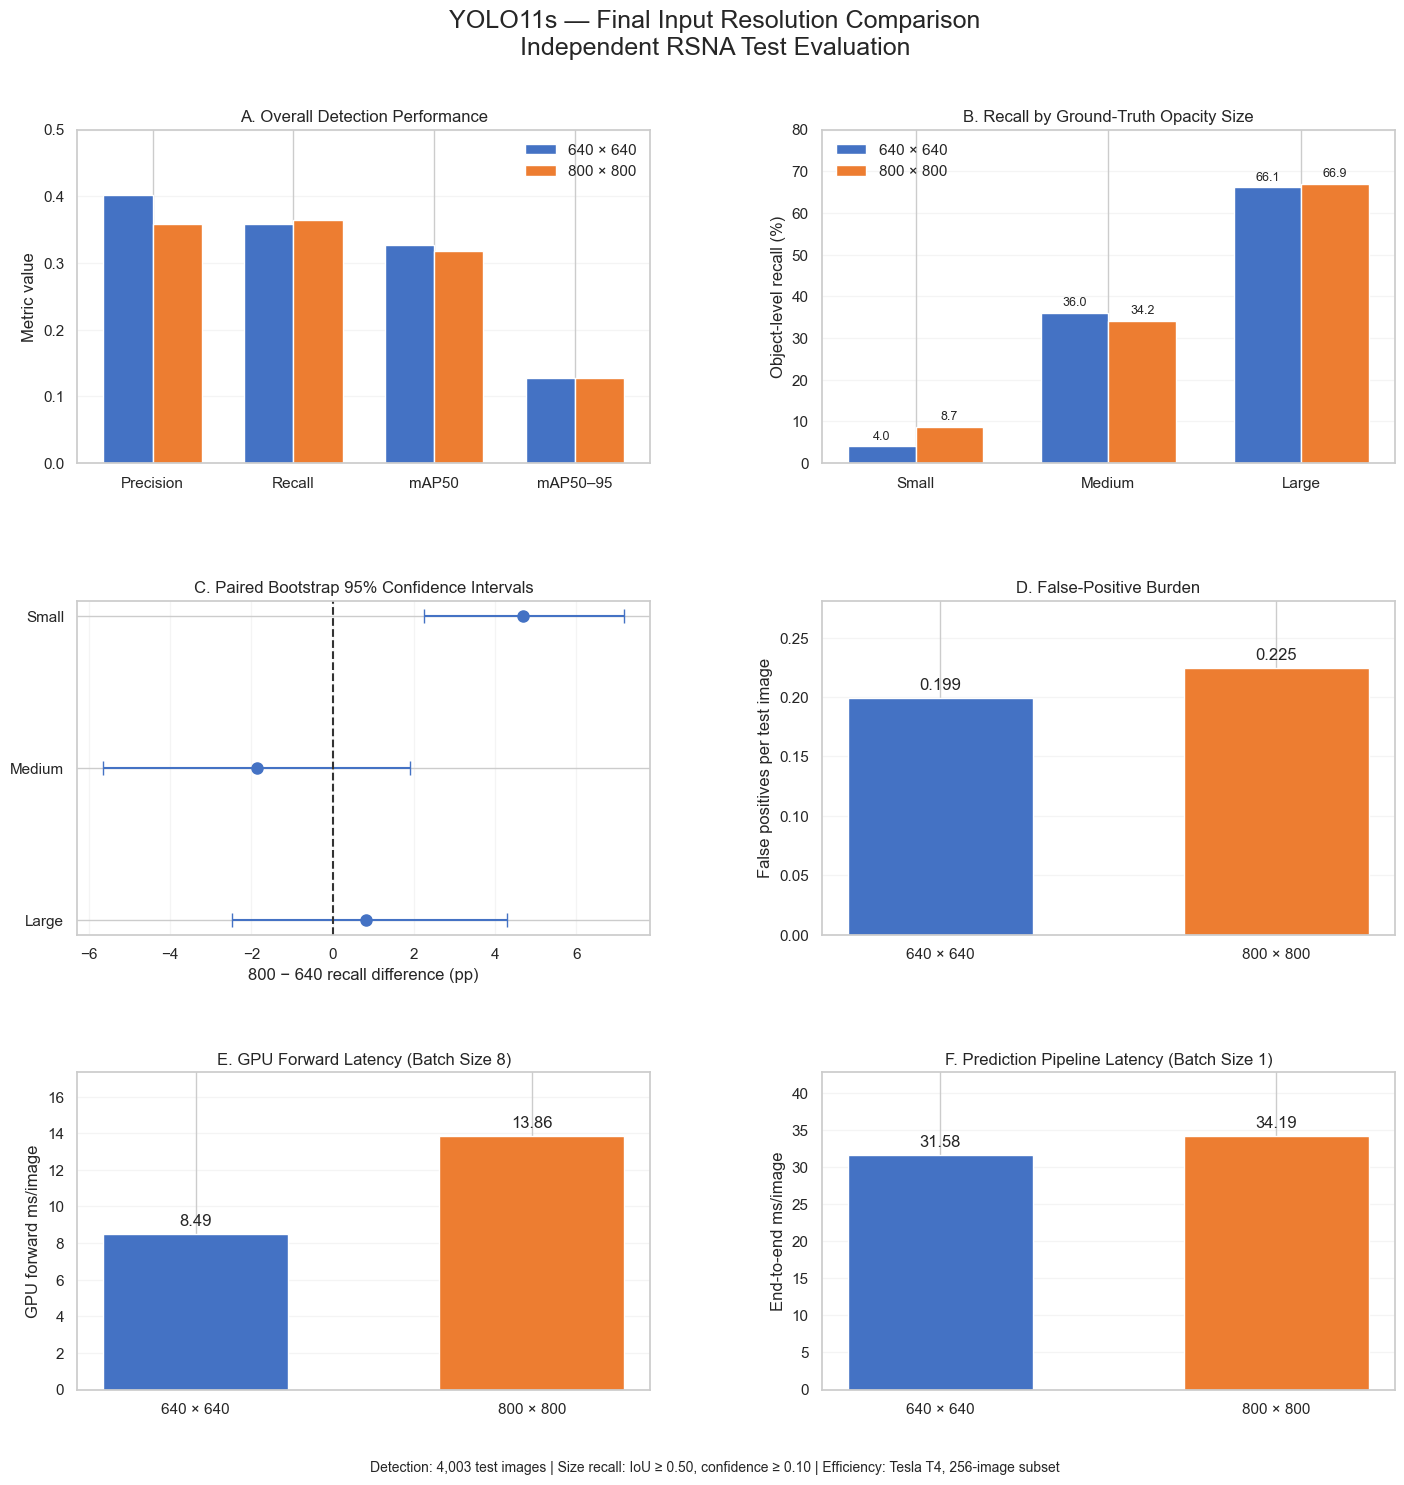


Research archive creation skipped. Previously downloaded archive preserved.

PHASE 6.5.1 — FINAL RESEARCH COMPARISON

MASTER RESULTS TABLE
                           metric  resolution_640  resolution_800  difference_800_minus_640 preferred_direction
                        Precision          0.4012          0.3590                   -0.0422              higher
             Recall (Ultralytics)          0.3588          0.3643                    0.0056              higher
                            mAP50          0.3264          0.3180                   -0.0083              higher
                         mAP50–95          0.1276          0.1278                    0.0002              higher
         Small-opacity recall (%)          4.0426          8.7234                    4.6809              higher
        Medium-opacity recall (%)         36.0248         34.1615                   -1.8634              higher
         Large-opacity recall (%)         66.1123         66.9439           

In [52]:

# ============================================================
# Phase 6.5.1 — Final Research Comparison and Archival
# YOLO11s: 640 × 640 vs 800 × 800
# Saved-results-first final research synthesis
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

# ------------------------------------------------------------
# 1. Configuration and saved research results
# ------------------------------------------------------------

CREATE_RESEARCH_ARCHIVE = False

final_dir = RESULTS_DIR / "final_comparison"
final_fig_dir = FIGURES_DIR / "final_comparison"

final_dir.mkdir(parents=True, exist_ok=True)
final_fig_dir.mkdir(parents=True, exist_ok=True)

test_dir = RESULTS_DIR / "test_evaluation"
size_dir = RESULTS_DIR / "size_analysis"
eff_dir = RESULTS_DIR / "efficiency_benchmark"

test_path = test_dir / "test_metrics_comparison.csv"
size_path = size_dir / "size_stratified_recall.csv"
recall_ci_path = size_dir / "paired_bootstrap_recall_ci.csv"
fp_ci_path = size_dir / "paired_bootstrap_fp_ci.csv"
eff_path = eff_dir / "efficiency_comparison.csv"

required_files = [
    test_path,
    size_path,
    recall_ci_path,
    fp_ci_path,
    eff_path
]

for path in required_files:
    assert path.is_file(), (
        f"Missing research evidence: {path}\n"
        "Restore the saved CSV from your research archive. "
        "Do not rerun training or inference."
    )

test_df = pd.read_csv(test_path)
size_df = pd.read_csv(size_path)
recall_ci = pd.read_csv(recall_ci_path)
fp_ci = pd.read_csv(fp_ci_path)
eff_df = pd.read_csv(eff_path)

# Handle resolution stored as a CSV index.
if "resolution" not in eff_df.columns:
    eff_df = eff_df.rename(
        columns={eff_df.columns[0]: "resolution"}
    )

for frame in (test_df, size_df, eff_df):
    frame["resolution"] = pd.to_numeric(
        frame["resolution"]
    ).astype(int)

assert set(test_df["resolution"]) == {640, 800}
assert set(size_df["resolution"]) == {640, 800}
assert set(eff_df["resolution"]) == {640, 800}

assert len(test_df) == 2
assert len(size_df) == 6
assert len(eff_df) == 2

assert not test_df["resolution"].duplicated().any()
assert not eff_df["resolution"].duplicated().any()

assert not size_df.duplicated(
    ["resolution", "size_category"]
).any()

test_df = test_df.set_index("resolution")
eff_df = eff_df.set_index("resolution")

# Load the recorded GPU identity, not the current session GPU.
benchmark_config_path = eff_dir / "benchmark_config.json"

if benchmark_config_path.is_file():
    with open(benchmark_config_path) as f:
        benchmark_config = json.load(f)

    gpu_label = benchmark_config.get(
        "gpu", "GPU not recorded"
    )
else:
    gpu_label = "GPU not recorded"

print("Completed research results loaded successfully.")
# ------------------------------------------------------------
# 2. Prepare comparable metrics
# ------------------------------------------------------------

size_pivot = size_df.pivot(
    index="size_category",
    columns="resolution",
    values="recall_at_iou50_conf010"
)

gt_pivot = size_df.pivot(
    index="size_category",
    columns="resolution",
    values="ground_truth_boxes"
)

categories = ["small", "medium", "large"]

assert set(size_pivot.index) == set(categories)
assert (gt_pivot[640] == gt_pivot[800]).all()
assert gt_pivot[640].sum() == 1434

assert set(recall_ci["size"].str.lower()) == set(categories)
assert len(recall_ci) == 3

assert set(fp_ci["population"]) == {
    "All test images",
    "Background-only images"
}
assert len(fp_ci) == 2

fp_all = fp_ci.loc[
    fp_ci["population"] == "All test images"
].iloc[0]

small_ci = recall_ci.loc[
    recall_ci["size"].str.lower() == "small"
].iloc[0]

# Verify that saved bootstrap point estimates match
# the corresponding size-recall results.
for size in categories:

    saved_difference = recall_ci.loc[
        recall_ci["size"].str.lower() == size,
        "difference_pp"
    ].iloc[0]

    expected_difference = (
        size_pivot.loc[size, 800]
        - size_pivot.loc[size, 640]
    ) * 100

    assert np.isclose(
        saved_difference,
        expected_difference,
        atol=1e-5
    ), f"Bootstrap difference mismatch: {size}"

# ------------------------------------------------------------
# 3. Build final master results comparison table
# ------------------------------------------------------------

metric_specs = [
    ("Precision", "precision", "test", "higher"),
    ("Recall (Ultralytics)", "recall", "test", "higher"),
    ("mAP50", "mAP50", "test", "higher"),
    ("mAP50–95", "mAP50_95", "test", "higher"),
    ("Small-opacity recall (%)", "small", "size", "higher"),
    ("Medium-opacity recall (%)", "medium", "size", "higher"),
    ("Large-opacity recall (%)", "large", "size", "higher"),
    ("False positives/image", "fp", "fp", "lower"),
    (
        "GPU forward latency (ms/image)",
        "gpu_forward_ms_per_image",
        "eff",
        "lower"
    ),
    (
        "GPU forward throughput (images/s)",
        "gpu_forward_throughput_fps",
        "eff",
        "higher"
    ),
    (
        "End-to-end latency (ms/image)",
        "pipeline_ms_per_image",
        "eff",
        "lower"
    ),
    (
        "End-to-end throughput (images/s)",
        "pipeline_throughput_fps",
        "eff",
        "higher"
    ),
    (
        "Peak allocated GPU memory (MiB)",
        "peak_gpu_memory_mib",
        "eff",
        "lower"
    )
]

master_rows = []

for label, key, source, direction in metric_specs:

    if source == "test":
        values = [
            float(test_df.loc[r, key])
            for r in (640, 800)
        ]

    elif source == "size":
        values = [
            float(size_pivot.loc[key, r] * 100)
            for r in (640, 800)
        ]

    elif source == "fp":
        values = [
            float(fp_all[f"fp_per_image_{r}"])
            for r in (640, 800)
        ]

    else:
        values = [
            float(eff_df.loc[r, key])
            for r in (640, 800)
        ]

    master_rows.append({
        "metric": label,
        "resolution_640": values[0],
        "resolution_800": values[1],
        "difference_800_minus_640": (
            values[1] - values[0]
        ),
        "preferred_direction": direction
    })

master_df = pd.DataFrame(master_rows)

assert len(master_df) == 13

master_path = final_dir / "master_results_comparison.csv"
master_df.to_csv(master_path, index=False)

# ------------------------------------------------------------
# 4. Final publication dashboard — six panels
# ------------------------------------------------------------

BLUE = "#4472C4"
ORANGE = "#ED7D31"

fig = plt.figure(figsize=(17, 15))

gs = fig.add_gridspec(
    3, 2,
    height_ratios=[1, 1, 0.95],
    hspace=0.42,
    wspace=0.30
)

# ------------------------------------------------------------
# Panel A — Overall held-out test detection metrics
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[0, 0])

overall_keys = [
    "precision", "recall", "mAP50", "mAP50_95"
]
overall_labels = [
    "Precision", "Recall", "mAP50", "mAP50–95"
]

x = np.arange(len(overall_keys))
width = 0.35

v640 = [
    test_df.loc[640, key] for key in overall_keys
]
v800 = [
    test_df.loc[800, key] for key in overall_keys
]

ax1.bar(
    x - width / 2,
    v640,
    width,
    label="640 × 640",
    color=BLUE
)

ax1.bar(
    x + width / 2,
    v800,
    width,
    label="800 × 800",
    color=ORANGE
)

ax1.set_xticks(x, overall_labels)
ax1.set_ylabel("Metric value")
ax1.set_ylim(0, 0.5)

ax1.set_title(
    "A. Overall Detection Performance",
    fontweight="bold"
)

ax1.legend(frameon=False)
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)

# ------------------------------------------------------------
# Panel B — Recall by ground-truth opacity size
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[0, 1])

x = np.arange(3)

r640 = (
    size_pivot.loc[categories, 640].to_numpy() * 100
)
r800 = (
    size_pivot.loc[categories, 800].to_numpy() * 100
)

bars1 = ax2.bar(
    x - width / 2,
    r640,
    width,
    color=BLUE,
    label="640 × 640"
)

bars2 = ax2.bar(
    x + width / 2,
    r800,
    width,
    color=ORANGE,
    label="800 × 800"
)

ax2.bar_label(
    bars1, fmt="%.1f", padding=3, fontsize=9
)
ax2.bar_label(
    bars2, fmt="%.1f", padding=3, fontsize=9
)

ax2.set_xticks(
    x, ["Small", "Medium", "Large"]
)
ax2.set_ylabel("Object-level recall (%)")
ax2.set_ylim(0, 80)

ax2.set_title(
    "B. Recall by Ground-Truth Opacity Size",
    fontweight="bold"
)

ax2.legend(frameon=False)
ax2.grid(axis="y", alpha=0.2)
ax2.set_axisbelow(True)

# ------------------------------------------------------------
# Panel C — Paired bootstrap recall confidence intervals
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[1, 0])

ci_plot = (
    recall_ci.assign(
        size=recall_ci["size"].str.capitalize()
    )
    .set_index("size")
    .loc[["Small", "Medium", "Large"]]
)

d = ci_plot["difference_pp"].to_numpy()
lo = d - ci_plot["ci_low_pp"].to_numpy()
hi = ci_plot["ci_high_pp"].to_numpy() - d

ax3.errorbar(
    d,
    np.arange(3),
    xerr=np.vstack([lo, hi]),
    fmt="o",
    capsize=5,
    markersize=8,
    color=BLUE
)

ax3.axvline(
    0, color="#333333", linestyle="--"
)

ax3.set_yticks(
    np.arange(3),
    ["Small", "Medium", "Large"]
)
ax3.invert_yaxis()
ax3.set_xlabel(
    "800 − 640 recall difference (pp)"
)

ax3.set_title(
    "C. Paired Bootstrap 95% Confidence Intervals",
    fontweight="bold"
)

ax3.grid(axis="x", alpha=0.2)

# ------------------------------------------------------------
# Panel D — False-positive burden
# ------------------------------------------------------------

ax4 = fig.add_subplot(gs[1, 1])

fp_values = [
    fp_all["fp_per_image_640"],
    fp_all["fp_per_image_800"]
]

bars = ax4.bar(
    ["640 × 640", "800 × 800"],
    fp_values,
    color=[BLUE, ORANGE],
    width=0.55
)

ax4.bar_label(
    bars, fmt="%.3f", padding=4
)

ax4.set_ylim(
    0, max(fp_values) * 1.25
)
ax4.set_ylabel(
    "False positives per test image"
)

ax4.set_title(
    "D. False-Positive Burden",
    fontweight="bold"
)

ax4.grid(axis="y", alpha=0.2)
ax4.set_axisbelow(True)

# ------------------------------------------------------------
# Panel E — GPU forward-pass latency
# ------------------------------------------------------------

ax5 = fig.add_subplot(gs[2, 0])

gpu_latency = [
    eff_df.loc[r, "gpu_forward_ms_per_image"]
    for r in (640, 800)
]

bars = ax5.bar(
    ["640 × 640", "800 × 800"],
    gpu_latency,
    color=[BLUE, ORANGE],
    width=0.55
)

ax5.bar_label(
    bars, fmt="%.2f", padding=4
)

ax5.set_ylim(
    0, max(gpu_latency) * 1.25
)
ax5.set_ylabel("GPU forward ms/image")

ax5.set_title(
    "E. GPU Forward Latency (Batch Size 8)",
    fontweight="bold"
)

ax5.grid(axis="y", alpha=0.2)
ax5.set_axisbelow(True)

# ------------------------------------------------------------
# Panel F — End-to-end prediction latency
# ------------------------------------------------------------

ax6 = fig.add_subplot(gs[2, 1])

pipeline_latency = [
    eff_df.loc[r, "pipeline_ms_per_image"]
    for r in (640, 800)
]

bars = ax6.bar(
    ["640 × 640", "800 × 800"],
    pipeline_latency,
    color=[BLUE, ORANGE],
    width=0.55
)

ax6.bar_label(
    bars, fmt="%.2f", padding=4
)

ax6.set_ylim(
    0, max(pipeline_latency) * 1.25
)
ax6.set_ylabel("End-to-end ms/image")

ax6.set_title(
    "F. Prediction Pipeline Latency (Batch Size 1)",
    fontweight="bold"
)

ax6.grid(axis="y", alpha=0.2)
ax6.set_axisbelow(True)

# ------------------------------------------------------------
# Dashboard title, methodology, and output
# ------------------------------------------------------------

fig.suptitle(
    "YOLO11s — Final Input Resolution Comparison\n"
    "Independent RSNA Test Evaluation",
    fontsize=18,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    "Detection: 4,003 test images | "
    "Size recall: IoU ≥ 0.50, confidence ≥ 0.10 | "
    f"Efficiency: {gpu_label}, 256-image subset",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    top=0.91,
    bottom=0.07
)

dashboard_png = (
    final_fig_dir / "final_research_dashboard.png"
)
dashboard_pdf = (
    final_fig_dir / "final_research_dashboard.pdf"
)

fig.savefig(
    dashboard_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    dashboard_pdf,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Research interpretation and metadata
# ------------------------------------------------------------

small_gain = (
    size_pivot.loc["small", 800]
    - size_pivot.loc["small", 640]
) * 100

fp_change = (
    fp_all["fp_per_image_800"]
    / fp_all["fp_per_image_640"]
    - 1
) * 100

gpu_change = (
    eff_df.loc[800, "gpu_forward_ms_per_image"]
    / eff_df.loc[640, "gpu_forward_ms_per_image"]
    - 1
) * 100

pipeline_change = (
    eff_df.loc[800, "pipeline_ms_per_image"]
    / eff_df.loc[640, "pipeline_ms_per_image"]
    - 1
) * 100

interpretation = {
    "research_question": (
        "How does increasing YOLO11s input resolution "
        "from 640 to 800 affect pulmonary opacity "
        "detection and computational efficiency?"
    ),
    "small_recall_difference_pp": float(small_gain),
    "small_recall_ci_95_pp": [
        float(small_ci["ci_low_pp"]),
        float(small_ci["ci_high_pp"])
    ],
    "false_positive_change_percent": float(fp_change),
    "gpu_forward_latency_change_percent": float(gpu_change),
    "pipeline_latency_change_percent": float(
        pipeline_change
    ),
    "conclusion": (
        "Higher input resolution improves observed "
        "small-opacity recall but increases false-positive "
        "burden and GPU computation. Aggregate detection "
        "accuracy remains similar."
    ),
    "limitations": [
        "Single training seed and checkpoint per resolution.",
        "Small-opacity recall remains low for both models.",
        "Bootstrap intervals capture image-sampling uncertainty.",
        "Size categories use relative bounding-box area.",
        "GPU memory estimates are session-dependent.",
        "No clinical deployment claims."
    ]
}

interpretation_path = (
    final_dir / "research_interpretation.json"
)

with open(interpretation_path, "w") as f:
    json.dump(
        interpretation,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 6. Optional research evidence archive
# ------------------------------------------------------------

archive_path = Path(
    "/kaggle/working/yolo11s_final_research_evidence.zip"
)

if CREATE_RESEARCH_ARCHIVE:

    import zipfile

    assert not archive_path.exists(), (
        f"Research archive already exists: {archive_path}\n"
        "Use CREATE_RESEARCH_ARCHIVE=False to preserve it."
    )

    evidence_dirs = [
        test_dir,
        size_dir,
        eff_dir,
        final_dir,
        FIGURES_DIR / "training_comparison",
        FIGURES_DIR / "test_comparison",
        FIGURES_DIR / "size_analysis",
        FIGURES_DIR / "efficiency_benchmark",
        final_fig_dir
    ]

    with zipfile.ZipFile(
        archive_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        added = set()

        for directory in evidence_dirs:

            if not directory.exists():
                continue

            for file_path in sorted(
                directory.rglob("*")
            ):

                if not file_path.is_file():
                    continue

                if file_path.suffix.lower() not in {
                    ".csv", ".json", ".png",
                    ".pdf", ".jpg", ".txt", ".yaml"
                }:
                    continue

                if file_path.is_relative_to(RESULTS_DIR):
                    relative = file_path.relative_to(
                        RESULTS_DIR
                    )
                    archive_name = (
                        Path("results") / relative
                    )

                elif file_path.is_relative_to(FIGURES_DIR):
                    relative = file_path.relative_to(
                        FIGURES_DIR
                    )
                    archive_name = (
                        Path("figures") / relative
                    )

                else:
                    continue

                archive_name = str(archive_name)

                if archive_name not in added:
                    archive.write(
                        file_path, archive_name
                    )
                    added.add(archive_name)

    print("\nResearch evidence archive created.")
    print(f"Archive: {archive_path}")

else:
    print(
        "\nResearch archive creation skipped. "
        "Previously downloaded archive preserved."
    )

# ------------------------------------------------------------
# 7. Final outputs and research findings
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("PHASE 6.5.1 — FINAL RESEARCH COMPARISON")
print("=" * 72)

print("\nMASTER RESULTS TABLE")
print(
    master_df.round(4).to_string(index=False)
)

print("\nKEY RESEARCH FINDINGS")

print(
    f"Small-opacity recall improvement: "
    f"{small_gain:+.2f} percentage points"
)

print(
    f"95% bootstrap CI: "
    f"[{small_ci['ci_low_pp']:+.2f}, "
    f"{small_ci['ci_high_pp']:+.2f}] pp"
)

print(
    f"False-positive burden change: "
    f"{fp_change:+.2f}%"
)

print(
    f"GPU forward latency change: "
    f"{gpu_change:+.2f}%"
)

print(
    f"End-to-end latency change: "
    f"{pipeline_change:+.2f}%"
)

print("\nSAVED ARTIFACTS")

print(f"Master table: {master_path}")
print(f"Dashboard PNG: {dashboard_png}")
print(f"Dashboard PDF: {dashboard_pdf}")
print(f"Interpretation JSON: {interpretation_path}")

if archive_path.is_file():

    print(f"Research archive: {archive_path}")

    print(
        f"Archive size: "
        f"{archive_path.stat().st_size / (1024**2):.2f} MiB"
    )

else:
    print(
        "Research archive: not present in this session "
        "(creation disabled)"
    )

print("\nPHASE 6.5.1 — COMPLETED")
print(
    f"Research archive regenerated: "
    f"{CREATE_RESEARCH_ARCHIVE}"
)
